# Synthetic Data Creation

### Pillar 1: Dual Player Numbering System & Squad Number Resolver

This module implements Pillar 1, establishing the PlayerRegistry (which assigns permanent sequential player_number integers 1..N and persistent latent skills) and the SquadNumberManager (which allocates realistic 1..99 club jersey numbers and resolves collisions when players switch clubs during the Mid-Season or End-of-Season transfer windows).

In [1]:
import numpy as np
import pandas as pd

# Set seed for reproducibility across pillars
SEED = 42
rng = np.random.default_rng(SEED)

# ==============================================================================
# PILLAR 1: DUAL PLAYER NUMBERING SYSTEM & SQUAD NUMBER COLLISION RESOLVER
# ==============================================================================

# Role-grounded jersey number pools (1 to 99)
GK_STARTER_POOL = [1, 13, 23]
GK_BACKUP_POOL = [12, 13, 22, 25, 31, 40, 1]
OUTFIELD_ATTACK_POOL = [9, 10, 11, 7, 8, 14, 17, 19, 20, 21]
OUTFIELD_DEPTH_POOL = (
    [2, 3, 4, 5, 6, 15, 16, 18, 24, 26, 27, 28, 29, 30]
    + list(range(32, 40))
    + list(range(41, 100))
)
ALL_JERSEY_NUMBERS = list(range(1, 100))


class PlayerRegistry:
    """
    Maintains the master registry of unique players across the 5-season universe.
    Assigns a permanent sequential integer `player_number` (1..N) and persistent
    latent penalty skills.
    """
    def __init__(self, rng_gen: np.random.Generator):
        self.rng = rng_gen
        self._next_player_number = 1
        self.players = []

    def register_player(
        self,
        role: str,
        tenure_category: str,
        active_seasons: list,
        first_season_window: str = "Full",
        last_season_window: str = "Full",
    ) -> dict:
        """
        Creates a new player with a permanent `player_number` (1, 2, 3, ...),
        a preferred jersey number, and latent skill parameters.
        """
        p_num = self._next_player_number
        self._next_player_number += 1

        # Pick an initial preferred squad number based on role
        if role == "GK":
            pref_pool = GK_STARTER_POOL + GK_BACKUP_POOL
        else:
            pref_pool = OUTFIELD_ATTACK_POOL + OUTFIELD_DEPTH_POOL[:15]
        preferred_squad_num = int(self.rng.choice(pref_pool))

        # Persistent latent skills (used later in Pillar 3)
        # Beta(37, 3) -> mean 92.5% on-target accuracy (~7.5% missed off-target)
        p_on_target = float(self.rng.beta(37.0, 3.0))
        kicker_skill = float(self.rng.normal(0.0, 0.35))  # theta_i
        gk_skill = float(self.rng.normal(0.0, 0.35))      # gamma_j

        player_record = {
            "player_number": p_num,  # Permanent integer ID (1..N)
            "player_name": f"{'GK' if role == 'GK' else 'Player'}_{p_num:03d}",
            "role": role,            # 'GK' or 'OUT'
            "tenure_category": tenure_category,
            "active_seasons": active_seasons,
            "num_seasons": len(active_seasons),
            "first_season_window": first_season_window,  # 'Full', 'H1_Only', or 'H2_Only'
            "last_season_window": last_season_window,    # 'Full', 'H1_Only', or 'H2_Only'
            "preferred_squad_number": preferred_squad_num,
            "p_on_target": p_on_target,
            "kicker_skill": kicker_skill,
            "gk_skill": gk_skill,
        }
        self.players.append(player_record)
        return player_record

    def to_dataframe(self) -> pd.DataFrame:
        return pd.DataFrame(self.players)


class SquadNumberManager:
    """
    Assigns club-specific `squad_number` (1..99) within each (season, half_season, club)
    and resolves collisions during Mid-Season (H1->H2) and End-of-Season transfers.
    """
    def __init__(self, rng_gen: np.random.Generator):
        self.rng = rng_gen
        # Tracks {(season_idx, half_season, club, player_number): squad_number}
        self.history = {}
        # Tracks a player's most recently worn squad number and club
        self.last_known_assignment = {}  # {player_number: (club, squad_number)}

    def _pick_available_number(self, candidate_pool: list, taken_numbers: set) -> int:
        for num in candidate_pool:
            if num not in taken_numbers:
                return int(num)
        # Fallback to any available number in 1..99
        for num in ALL_JERSEY_NUMBERS:
            if num not in taken_numbers:
                return int(num)
        raise ValueError("Club roster exceeded 99 players!")

    def assign_club_half_squad_numbers(
        self,
        season_idx: int,
        half_season: str,
        club: str,
        club_roster_df: pd.DataFrame,
    ) -> dict:
        """
        Given all active players on `club` in `(season_idx, half_season)`,
        assigns a unique `squad_number` (1..99) to each `player_number`.
        - Incumbents staying at the same club keep their current squad_number.
        - Incoming transfers/arrivals keep their previous/preferred squad_number if free;
          otherwise they receive a role-appropriate available number.
        """
        taken_numbers = set()
        assigned = {}

        # Separate incumbents (stayed at the same club from previous window) vs newcomers
        incumbents = []
        newcomers = []

        for _, row in club_roster_df.iterrows():
            p_num = int(row["player_number"])
            prev = self.last_known_assignment.get(p_num, None)
            if prev is not None and prev[0] == club:
                incumbents.append((row, prev[1]))
            else:
                newcomers.append(row)

        # 1. Lock in incumbent squad numbers first (100% persistence at same club)
        for row, prev_sq_num in incumbents:
            p_num = int(row["player_number"])
            assigned[p_num] = prev_sq_num
            taken_numbers.add(prev_sq_num)

        # 2. Sort newcomers so Starters & Primary Takers get priority on prime numbers
        newcomers_sorted = sorted(
            newcomers,
            key=lambda r: float(r.get("selection_weight", 0.0)),
            reverse=True,
        )

        for row in newcomers_sorted:
            p_num = int(row["player_number"])
            role = row["role"]
            hierarchy_tier = row.get("hierarchy_tier", "Depth")
            pref_num = int(row["preferred_squad_number"])

            # Check if player had a squad number at their previous club
            prev = self.last_known_assignment.get(p_num, None)
            desired_num = prev[1] if prev is not None else pref_num

            # Build role-grounded priority list starting with desired_num
            if role == "GK":
                if hierarchy_tier == "Primary_GK":
                    pool = GK_STARTER_POOL + [desired_num] + GK_BACKUP_POOL
                else:
                    pool = [desired_num] + GK_BACKUP_POOL + GK_STARTER_POOL
            else:
                if hierarchy_tier in ("Primary_Taker", "Secondary_Taker"):
                    pool = [desired_num] + OUTFIELD_ATTACK_POOL + OUTFIELD_DEPTH_POOL
                else:
                    pool = [desired_num] + OUTFIELD_DEPTH_POOL + OUTFIELD_ATTACK_POOL

            chosen_sq_num = self._pick_available_number(pool, taken_numbers)
            assigned[p_num] = chosen_sq_num
            taken_numbers.add(chosen_sq_num)

        # Update tracking state
        for p_num, sq_num in assigned.items():
            self.history[(season_idx, half_season, club, p_num)] = sq_num
            self.last_known_assignment[p_num] = (club, sq_num)

        # Strict uniqueness verification within (season, half_season, club)
        assert len(assigned) == len(set(assigned.values())), (
            f"Duplicate squad_number detected in {club} ({season_idx}, {half_season})!"
        )
        return assigned


# ==============================================================================
# PILLAR 1 VERIFICATION DEMO
# ==============================================================================
if __name__ == "__main__":
    demo_registry = PlayerRegistry(rng)
    demo_sq_mgr = SquadNumberManager(rng)

    # Register 4 sample players (2 GKs, 2 Primary Takers who both want #9)
    p1 = demo_registry.register_player("GK", "5_Seasons", [0, 1, 2, 3, 4])
    p2 = demo_registry.register_player("GK", "2_Seasons", [0, 1])
    p3 = demo_registry.register_player("OUT", "5_Seasons", [0, 1, 2, 3, 4])
    p4 = demo_registry.register_player("OUT", "3_Seasons", [0, 1, 2])

    # Force p3 and p4 to both prefer #9 to test transfer collision resolution
    p3["preferred_squad_number"] = 9
    p4["preferred_squad_number"] = 9

    # Half 1 (H1): p1, p2, p3 at Club_01; p4 at Club_02 (wearing #9)
    club1_h1 = pd.DataFrame([
        {**p1, "hierarchy_tier": "Primary_GK", "selection_weight": 0.85},
        {**p2, "hierarchy_tier": "Backup_GK", "selection_weight": 0.15},
        {**p3, "hierarchy_tier": "Primary_Taker", "selection_weight": 0.65},
    ])
    club2_h1 = pd.DataFrame([
        {**p4, "hierarchy_tier": "Primary_Taker", "selection_weight": 0.65},
    ])

    sq_c1_h1 = demo_sq_mgr.assign_club_half_squad_numbers(0, "H1", "Club_01", club1_h1)
    sq_c2_h1 = demo_sq_mgr.assign_club_half_squad_numbers(0, "H1", "Club_02", club2_h1)

    # Half 2 (H2): Mid-Season Transfer! p4 transfers from Club_02 to Club_01
    # p3 is the incumbent #9 at Club_01, so p4 must get bumped to the next attacking number (#10)
    club1_h2 = pd.DataFrame([
        {**p1, "hierarchy_tier": "Primary_GK", "selection_weight": 0.85},
        {**p2, "hierarchy_tier": "Backup_GK", "selection_weight": 0.15},
        {**p3, "hierarchy_tier": "Primary_Taker", "selection_weight": 0.65},
        {**p4, "hierarchy_tier": "Secondary_Taker", "selection_weight": 0.15},
    ])
    sq_c1_h2 = demo_sq_mgr.assign_club_half_squad_numbers(0, "H2", "Club_01", club1_h2)

    print("H1 Club_01 Squad Numbers (player_number -> squad_number):", sq_c1_h1)
    print("H1 Club_02 Squad Numbers (player_number -> squad_number):", sq_c2_h1)
    print("H2 Club_01 Squad Numbers after Player #4 transfers in:  ", sq_c1_h2)

H1 Club_01 Squad Numbers (player_number -> squad_number): {1: 1, 3: 9, 2: 31}
H1 Club_02 Squad Numbers (player_number -> squad_number): {4: 9}
H2 Club_01 Squad Numbers after Player #4 transfers in:   {1: 1, 2: 31, 3: 9, 4: 10}


### Pillar 2: Two-Window Calendar, 250-Player Cohort Engine & Random Club Assignment

This module implements Pillar 2, connecting directly to PlayerRegistry and SquadNumberManager from Pillar 1. It builds the 5-season universe (2021/22 to 2025/26), enforces 250 unique active players per season (40 Goalkeepers and 210 Outfield Players), models the Mid-Season (Jan 15/16) and End-of-Season (Summer) transfer windows, guarantees every Premier League team has valid goalkeepers and kickers in both H1 and H2, and resolves jersey numbers via Pillar 1.

In [2]:
import numpy as np
import pandas as pd

# ==============================================================================
# PILLAR 2: TWO-WINDOW CALENDAR, 250-PLAYER COHORTS & RANDOM CLUB TRANSFERS
# ==============================================================================

SEASONS = ["2021/22", "2022/23", "2023/24", "2024/25", "2025/26"]
SEASON_START_YEARS = [2021, 2022, 2023, 2024, 2025]
CLUBS = [f"EPL_Club_{i:02d}" for i in range(1, 21)]  # 20 Premier League teams

GKS_PER_SEASON = 40        # Strictly 40 unique GKs per season
OUTFIELD_PER_SEASON = 210  # Strictly 210 unique Outfielders per season
TOTAL_PLAYERS_PER_SEASON = GKS_PER_SEASON + OUTFIELD_PER_SEASON  # 250

MID_SEASON_TRANSFER_PROB = 0.12  # 12% of full-season players switch EPL clubs in Jan
END_SEASON_TRANSFER_PROB = 0.22  # 22% of returning players switch EPL clubs in Summer


class CohortAndRosterEngine:
    """
    Constructs the 5-season player pool (strictly 250 unique active players/season),
    manages H1 (Aug 15 - Jan 15) and H2 (Jan 16 - May 25) active windows,
    assigns players randomly to the 20 EPL clubs with minimum roster safeguards,
    and executes Mid-Season and End-of-Season transfer windows.
    """
    def __init__(
        self,
        registry: PlayerRegistry,
        squad_mgr: SquadNumberManager,
        rng_gen: np.random.Generator,
    ):
        self.registry = registry
        self.squad_mgr = squad_mgr
        self.rng = rng_gen

    def generate_player_cohorts(self) -> pd.DataFrame:
        """
        Generates multi-season (5, 4, 3, 2 seasons) and single-season
        (1_Full_Season, Partial_H1_Only, Partial_H2_Only) cohorts so that
        every season has EXACTLY 40 GKs and 210 Outfield players.
        """
        # 1. Define Multi-Season Contiguous Stints (Role, Season Indices, Count, Label)
        multi_season_specs = [
            # Goalkeepers (Multi-season core)
            ("GK", [0, 1, 2, 3, 4], 12, "5_Seasons"),
            ("GK", [0, 1, 2, 3], 4, "4_Seasons"),
            ("GK", [1, 2, 3, 4], 4, "4_Seasons"),
            ("GK", [0, 1, 2], 3, "3_Seasons"),
            ("GK", [1, 2, 3], 3, "3_Seasons"),
            ("GK", [2, 3, 4], 3, "3_Seasons"),
            ("GK", [0, 1], 3, "2_Seasons"),
            ("GK", [1, 2], 3, "2_Seasons"),
            ("GK", [2, 3], 3, "2_Seasons"),
            ("GK", [3, 4], 3, "2_Seasons"),

            # Outfield Players (Multi-season core)
            ("OUT", [0, 1, 2, 3, 4], 68, "5_Seasons"),
            ("OUT", [0, 1, 2, 3], 18, "4_Seasons"),
            ("OUT", [1, 2, 3, 4], 18, "4_Seasons"),
            ("OUT", [0, 1, 2], 14, "3_Seasons"),
            ("OUT", [1, 2, 3], 14, "3_Seasons"),
            ("OUT", [2, 3, 4], 14, "3_Seasons"),
            ("OUT", [0, 1], 14, "2_Seasons"),
            ("OUT", [1, 2], 14, "2_Seasons"),
            ("OUT", [2, 3], 14, "2_Seasons"),
            ("OUT", [3, 4], 14, "2_Seasons"),
        ]

        for role, seasons_list, count, label in multi_season_specs:
            for _ in range(count):
                # 20% of multi-season players arrive in Jan (H2_Only) of their first season
                # or depart in Jan (H1_Only) of their final season
                first_win = "H2_Only" if self.rng.random() < 0.15 else "Full"
                last_win = "H1_Only" if self.rng.random() < 0.15 else "Full"
                self.registry.register_player(
                    role=role,
                    tenure_category=label,
                    active_seasons=seasons_list,
                    first_season_window=first_win,
                    last_season_window=last_win,
                )

        # 2. Count active players per season so far and top up each season to
        # strictly 40 GKs and 210 Outfield players using 1-Full and Partial-Season players
        for s_idx in range(len(SEASONS)):
            current_players = self.registry.players
            active_gks = sum(
                1 for p in current_players
                if p["role"] == "GK" and s_idx in p["active_seasons"]
            )
            active_out = sum(
                1 for p in current_players
                if p["role"] == "OUT" and s_idx in p["active_seasons"]
            )

            gk_needed = GKS_PER_SEASON - active_gks
            for i in range(gk_needed):
                if i < gk_needed // 2:
                    self.registry.register_player("GK", "1_Full_Season", [s_idx], "Full", "Full")
                elif i % 2 == 0:
                    self.registry.register_player("GK", "Partial_H1_Only", [s_idx], "H1_Only", "H1_Only")
                else:
                    self.registry.register_player("GK", "Partial_H2_Only", [s_idx], "H2_Only", "H2_Only")

            out_needed = OUTFIELD_PER_SEASON - active_out
            for i in range(out_needed):
                if i < int(out_needed * 0.55):
                    self.registry.register_player("OUT", "1_Full_Season", [s_idx], "Full", "Full")
                elif i % 2 == 0:
                    self.registry.register_player("OUT", "Partial_H1_Only", [s_idx], "H1_Only", "H1_Only")
                else:
                    self.registry.register_player("OUT", "Partial_H2_Only", [s_idx], "H2_Only", "H2_Only")

        return self.registry.to_dataframe()

    def _assign_clubs_with_safeguard(
        self,
        active_df: pd.DataFrame,
        prev_club_map: dict,
        transfer_prob: float,
    ) -> tuple[dict, dict]:
        """
        Assigns every active player in a half-season to one of the 20 EPL clubs.
        - Returning players stay at their previous club unless they trigger a transfer
          (with probability `transfer_prob`).
        - New arrivals are assigned randomly.
        - Safeguard guarantees every club has >= 1 active GK and >= 5 active Outfielders.
        """
        club_assignment = {}
        transferred_flag = {}

        # Step A: Initial assignment (keep club or transfer/randomly assign)
        for _, row in active_df.iterrows():
            p_num = int(row["player_number"])
            if p_num in prev_club_map:
                if self.rng.random() < transfer_prob:
                    other_clubs = [c for c in CLUBS if c != prev_club_map[p_num]]
                    club_assignment[p_num] = str(self.rng.choice(other_clubs))
                    transferred_flag[p_num] = True
                else:
                    club_assignment[p_num] = prev_club_map[p_num]
                    transferred_flag[p_num] = False
            else:
                club_assignment[p_num] = str(self.rng.choice(CLUBS))
                transferred_flag[p_num] = True  # New entry to league

        # Step B: Enforce Safeguard >= 1 GK per club
        gk_ids = active_df[active_df["role"] == "GK"]["player_number"].astype(int).tolist()
        for club in CLUBS:
            club_gks = [p for p in gk_ids if club_assignment[p] == club]
            if len(club_gks) == 0:
                # Reassign a GK from a club that currently has >= 2 GKs
                donor_clubs = [
                    c for c in CLUBS
                    if sum(1 for p in gk_ids if club_assignment[p] == c) >= 2
                ]
                donor_club = str(self.rng.choice(donor_clubs))
                donor_gks = [p for p in gk_ids if club_assignment[p] == donor_club]
                chosen_gk = int(self.rng.choice(donor_gks))
                club_assignment[chosen_gk] = club
                transferred_flag[chosen_gk] = (
                    prev_club_map.get(chosen_gk, club) != club
                )

        # Step C: Enforce Safeguard >= 5 Outfielders per club
        out_ids = active_df[active_df["role"] == "OUT"]["player_number"].astype(int).tolist()
        for club in CLUBS:
            while sum(1 for p in out_ids if club_assignment[p] == club) < 5:
                donor_clubs = [
                    c for c in CLUBS
                    if sum(1 for p in out_ids if club_assignment[p] == c) > 8
                ]
                donor_club = str(self.rng.choice(donor_clubs))
                donor_outs = [p for p in out_ids if club_assignment[p] == donor_club]
                chosen_out = int(self.rng.choice(donor_outs))
                club_assignment[chosen_out] = club
                transferred_flag[chosen_out] = (
                    prev_club_map.get(chosen_out, club) != club
                )

        return club_assignment, transferred_flag

    def build_half_season_rosters(self) -> pd.DataFrame:
        """
        Expands player cohorts across the 10 half-season windows (5 seasons x H1/H2),
        executes End-of-Season and Mid-Season transfers, sets club penalty hierarchies,
        and assigns unique club squad numbers via Pillar 1.
        """
        df_players = self.generate_player_cohorts()

        # Build player-season participation records
        season_participation = []
        for _, p in df_players.iterrows():
            seasons_list = p["active_seasons"]
            for idx, s_idx in enumerate(seasons_list):
                if len(seasons_list) == 1:
                    win = p["first_season_window"]
                elif idx == 0:
                    win = p["first_season_window"]
                elif idx == len(seasons_list) - 1:
                    win = p["last_season_window"]
                else:
                    win = "Full"

                active_h1 = win in ("Full", "H1_Only")
                active_h2 = win in ("Full", "H2_Only")
                season_participation.append({
                    "player_number": int(p["player_number"]),
                    "player_name": p["player_name"],
                    "role": p["role"],
                    "tenure_category": p["tenure_category"],
                    "preferred_squad_number": int(p["preferred_squad_number"]),
                    "p_on_target": float(p["p_on_target"]),
                    "kicker_skill": float(p["kicker_skill"]),
                    "gk_skill": float(p["gk_skill"]),
                    "season_idx": s_idx,
                    "season": SEASONS[s_idx],
                    "season_window_profile": win,
                    "active_H1": active_h1,
                    "active_H2": active_h2,
                })

        df_part = pd.DataFrame(season_participation)

        # Verify strictly 250 unique active players per season (40 GK, 210 OUT)
        for s_idx, s_name in enumerate(SEASONS):
            s_sub = df_part[df_part["season_idx"] == s_idx]
            n_gk = (s_sub["role"] == "GK").sum()
            n_out = (s_sub["role"] == "OUT").sum()
            assert n_gk == GKS_PER_SEASON and n_out == OUTFIELD_PER_SEASON, (
                f"Season {s_name} failed cap check: {n_gk} GKs, {n_out} Outfielders"
            )

        # Iterate chronologically through all 10 half-seasons (S1 H1 -> S5 H2)
        prev_club_map = {}
        prev_hierarchy_weight = {}
        half_season_rows = []

        for s_idx, s_name in enumerate(SEASONS):
            yr = SEASON_START_YEARS[s_idx]
            for half in ["H1", "H2"]:
                is_h1 = half == "H1"
                col_flag = "active_H1" if is_h1 else "active_H2"
                transfer_prob = END_SEASON_TRANSFER_PROB if (is_h1 and s_idx > 0) else (
                    0.0 if (is_h1 and s_idx == 0) else MID_SEASON_TRANSFER_PROB
                )

                active_half_df = df_part[
                    (df_part["season_idx"] == s_idx) & (df_part[col_flag])
                ].copy()

                # Assign clubs for this half-season window
                club_map, transfer_flags = self._assign_clubs_with_safeguard(
                    active_half_df, prev_club_map, transfer_prob
                )
                active_half_df["club"] = active_half_df["player_number"].map(club_map)
                active_half_df["transferred_in_window"] = active_half_df["player_number"].map(transfer_flags)

                # Date boundaries for this half-season
                if is_h1:
                    date_from = pd.Timestamp(f"{yr}-08-15")
                    date_to = pd.Timestamp(f"{yr+1}-01-15")
                else:
                    date_from = pd.Timestamp(f"{yr+1}-01-16")
                    date_to = pd.Timestamp(f"{yr+1}-05-25")

                # Within each club, assign Hierarchy Tier, Selection Weights, and Squad Numbers
                for club in CLUBS:
                    club_df = active_half_df[active_half_df["club"] == club].copy()

                    # Separate GKs and Outfielders to assign selection weights
                    gk_sub = club_df[club_df["role"] == "GK"].copy()
                    out_sub = club_df[club_df["role"] == "OUT"].copy()

                    # Sort so incumbents who were starters/primary takers keep their spot
                    gk_sub["prev_w"] = gk_sub["player_number"].map(
                        lambda p: prev_hierarchy_weight.get((club, p), self.rng.random() * 0.1)
                    )
                    gk_sub = gk_sub.sort_values("prev_w", ascending=False)

                    out_sub["prev_w"] = out_sub["player_number"].map(
                        lambda p: prev_hierarchy_weight.get((club, p), self.rng.random() * 0.1)
                    )
                    out_sub = out_sub.sort_values("prev_w", ascending=False)

                    # Assign GK weights (85% starter, 15% split among backups)
                    n_gks = len(gk_sub)
                    if n_gks == 1:
                        gk_tiers = ["Primary_GK"]
                        gk_weights = [1.0]
                    else:
                        gk_tiers = ["Primary_GK"] + ["Backup_GK"] * (n_gks - 1)
                        gk_weights = [0.85] + [0.15 / (n_gks - 1)] * (n_gks - 1)
                    gk_sub["hierarchy_tier"] = gk_tiers
                    gk_sub["selection_weight"] = gk_weights

                    # Assign Outfield kicker weights (65% Primary, 15% + 10% Secondary, 10% Depth)
                    n_out = len(out_sub)
                    out_tiers = []
                    out_weights = []
                    depth_count = max(1, n_out - 3)
                    for rank_idx in range(n_out):
                        if rank_idx == 0:
                            out_tiers.append("Primary_Taker")
                            out_weights.append(0.65)
                        elif rank_idx == 1:
                            out_tiers.append("Secondary_Taker")
                            out_weights.append(0.15)
                        elif rank_idx == 2:
                            out_tiers.append("Secondary_Taker")
                            out_weights.append(0.10)
                        else:
                            out_tiers.append("Depth_Kicker")
                            out_weights.append(0.10 / depth_count)
                    out_sub["hierarchy_tier"] = out_tiers
                    out_sub["selection_weight"] = out_weights

                    combined_club_df = pd.concat([gk_sub, out_sub], ignore_index=True)

                    # Call Pillar 1 SquadNumberManager to assign unique jersey numbers (1..99)
                    sq_map = self.squad_mgr.assign_club_half_squad_numbers(
                        season_idx=s_idx,
                        half_season=half,
                        club=club,
                        club_roster_df=combined_club_df,
                    )
                    combined_club_df["squad_number"] = combined_club_df["player_number"].map(sq_map)

                    for _, r in combined_club_df.iterrows():
                        p_num = int(r["player_number"])
                        prev_club_map[p_num] = club
                        prev_hierarchy_weight[(club, p_num)] = float(r["selection_weight"])

                        half_season_rows.append({
                            "season_idx": s_idx,
                            "season": s_name,
                            "half_season": half,
                            "active_from": date_from,
                            "active_to": date_to,
                            "club": club,
                            "player_number": p_num,
                            "squad_number": int(r["squad_number"]),
                            "player_name": r["player_name"],
                            "role": r["role"],
                            "tenure_category": r["tenure_category"],
                            "season_window_profile": r["season_window_profile"],
                            "hierarchy_tier": r["hierarchy_tier"],
                            "selection_weight": round(float(r["selection_weight"]), 4),
                            "transferred_in_window": bool(r["transferred_in_window"]),
                            "p_on_target": float(r["p_on_target"]),
                            "kicker_skill": float(r["kicker_skill"]),
                            "gk_skill": float(r["gk_skill"]),
                        })

        return pd.DataFrame(half_season_rows)


# ==============================================================================
# PILLAR 2 VERIFICATION & AUDIT
# ==============================================================================
if __name__ == "__main__":
    registry = PlayerRegistry(rng)
    squad_mgr = SquadNumberManager(rng)
    roster_engine = CohortAndRosterEngine(registry, squad_mgr, rng)

    df_half_rosters = roster_engine.build_half_season_rosters()
    df_master_players = registry.to_dataframe()

    print(f"Total Unique Players Generated Across 5 Seasons: {len(df_master_players)}")
    print("\n--- SEASON CAP AUDIT (Unique Active Players per Season by Role) ---")
    season_audit = (
        df_half_rosters.groupby(["season", "role"])["player_number"]
        .nunique()
        .unstack()
    )
    season_audit["Total_Unique_Players"] = season_audit["GK"] + season_audit["OUT"]
    print(season_audit)

    print("\n--- SEASON WINDOW PROFILE BREAKDOWN (Unique Players per Season) ---")
    win_audit = (
        df_half_rosters.groupby(["season", "season_window_profile"])["player_number"]
        .nunique()
        .unstack(fill_value=0)
    )
    print(win_audit)

    print("\n--- SAMPLE HALF-SEASON ROSTER ROWS (With Permanent & Jersey Numbers) ---")
    sample_cols = [
        "season", "half_season", "club", "player_number",
        "squad_number", "player_name", "role", "hierarchy_tier", "transferred_in_window"
    ]
    print(df_half_rosters[sample_cols].head(10).to_string(index=False))

Total Unique Players Generated Across 5 Seasons: 628

--- SEASON CAP AUDIT (Unique Active Players per Season by Role) ---
role     GK  OUT  Total_Unique_Players
season                                
2021/22  40  210                   250
2022/23  40  210                   250
2023/24  40  210                   250
2024/25  40  210                   250
2025/26  40  210                   250

--- SEASON WINDOW PROFILE BREAKDOWN (Unique Players per Season) ---
season_window_profile  Full  H1_Only  H2_Only
season                                       
2021/22                 178       26       46
2022/23                 216       14       20
2023/24                 222       15       13
2024/25                 214       21       15
2025/26                 176       47       27

--- SAMPLE HALF-SEASON ROSTER ROWS (With Permanent & Jersey Numbers) ---
 season half_season        club  player_number  squad_number player_name role  hierarchy_tier  transferred_in_window
2021/22          H1 EPL

### Pillar 3: Two-Stage Generative Penalty Physics & Datasets 1, 2, and 3

This module implements Pillar 3, taking the half-season rosters from Pillar 2 to simulate individual penalty kicks across all 10 half-season windows (2021/22 H1 through 2025/26 H2). It resolves every kick in two sequential stages (Frame Accuracy followed by the Bradley-Terry 1v1 Duel with persistent pairwise stylistic interaction $\delta_{ij}$) to build Dataset 3 (dataset_3_matchup_events), and then performs bottom-up aggregations to construct Dataset 1 (dataset_1_kickers) and Dataset 2 (dataset_2_goalkeepers).

In [4]:
import numpy as np
import pandas as pd

# ==============================================================================
# PILLAR 3: TWO-STAGE PENALTY SIMULATOR & BOTTOM-UP AGGREGATION (DATASETS 1-3)
# ==============================================================================

AVG_PKS_PER_HALF_SEASON = 51.5  # ~103 penalties per full Premier League season
BASE_ON_TARGET_STOP_RATE = 0.15  # 15% GK save rate on target (~78.6% overall conversion)
BASE_STOP_LOGIT = float(np.log(BASE_ON_TARGET_STOP_RATE / (1.0 - BASE_ON_TARGET_STOP_RATE)))
PAIRWISE_H2H_SIGMA = 0.25        # Standard deviation for persistent stylistic matchup delta_ij


class PenaltySimulationEngine:
    """
    Simulates penalty events across the 5-season (10 half-season) universe
    and derives Dataset 1 (Kickers), Dataset 2 (Goalkeepers), and Dataset 3 (Matchups).
    """
    def __init__(
        self,
        df_master_players: pd.DataFrame,
        df_half_rosters: pd.DataFrame,
        rng_gen: np.random.Generator,
    ):
        self.df_players = df_master_players
        self.df_rosters = df_half_rosters
        self.rng = rng_gen
        # Persistent pairwise interaction cache: {(kicker_number, gk_number): delta_ij}
        self.pairwise_deltas = {}

    def _get_pairwise_delta(self, kicker_num: int, gk_num: int) -> float:
        """
        Returns the persistent stylistic matchup effect delta_ij between
        kicker_number i and gk_number j.
        """
        pair_key = (int(kicker_num), int(gk_num))
        if pair_key not in self.pairwise_deltas:
            self.pairwise_deltas[pair_key] = float(
                self.rng.normal(0.0, PAIRWISE_H2H_SIGMA)
            )
        return self.pairwise_deltas[pair_key]

    def simulate_dataset_3_events(self) -> pd.DataFrame:
        """
        Generates Dataset 3: Chronological event log of Kicker A vs. Goalkeeper B on Date X.
        """
        events = []
        event_counter = 1

        # Group rosters by (season_idx, half_season) for fast lookup
        for (s_idx, half), half_roster in self.df_rosters.groupby(
            ["season_idx", "half_season"], sort=False
        ):
            season_str = half_roster["season"].iloc[0]
            date_from = half_roster["active_from"].iloc[0]
            date_to = half_roster["active_to"].iloc[0]
            window_days = (date_to - date_from).days

            # Draw number of penalties in this half-season from Poisson(51.5)
            n_pks = int(self.rng.poisson(AVG_PKS_PER_HALF_SEASON))

            # Pre-split by club and role for fast sampling
            clubs_in_half = half_roster["club"].unique().tolist()

            for _ in range(n_pks):
                # Sample random match date within this half-season window
                offset_days = int(self.rng.integers(0, window_days + 1))
                match_date = date_from + pd.Timedelta(days=offset_days)
                minute = int(self.rng.integers(1, 96))

                # Sample Kicker Club and Opposing Goalkeeper Club
                kicker_club, gk_club = self.rng.choice(
                    clubs_in_half, size=2, replace=False
                )

                # Filter eligible kickers on kicker_club and eligible GKs on gk_club
                cand_kickers = half_roster[
                    (half_roster["club"] == kicker_club) & (half_roster["role"] == "OUT")
                ]
                cand_gks = half_roster[
                    (half_roster["club"] == gk_club) & (half_roster["role"] == "GK")
                ]

                # Sample Kicker A and Goalkeeper B using their half-season selection weights
                k_weights = cand_kickers["selection_weight"].to_numpy(dtype=float)
                k_probs = k_weights / k_weights.sum()
                kicker_idx = self.rng.choice(cand_kickers.index, p=k_probs)
                kicker = cand_kickers.loc[kicker_idx]

                g_weights = cand_gks["selection_weight"].to_numpy(dtype=float)
                g_probs = g_weights / g_weights.sum()
                gk_idx = self.rng.choice(cand_gks.index, p=g_probs)
                gk = cand_gks.loc[gk_idx]

                k_num = int(kicker["player_number"])
                g_num = int(gk["player_number"])

                # --------------------------------------------------------------
                # STAGE 1: FRAME ACCURACY (On-Target vs. Missed_Off_Target)
                # --------------------------------------------------------------
                is_on_target = self.rng.random() <= float(kicker["p_on_target"])

                if not is_on_target:
                    outcome = "Missed_Off_Target"
                    p_stop_given_on_target = np.nan
                else:
                    # ----------------------------------------------------------
                    # STAGE 2: 1v1 DUEL GIVEN ON-TARGET (Bradley-Terry + H2H)
                    # ----------------------------------------------------------
                    delta_ij = self._get_pairwise_delta(k_num, g_num)
                    logit_stop = (
                        BASE_STOP_LOGIT
                        + float(gk["gk_skill"])
                        - float(kicker["kicker_skill"])
                        + delta_ij
                    )
                    p_stop_given_on_target = float(1.0 / (1.0 + np.exp(-logit_stop)))
                    outcome = (
                        "Stopped_by_GK"
                        if self.rng.random() < p_stop_given_on_target
                        else "Converted"
                    )

                events.append({
                    "event_id": f"PK_{event_counter:04d}",
                    "season_idx": int(s_idx),
                    "season": season_str,
                    "half_season": half,
                    "date": match_date.strftime("%Y-%m-%d"),
                    "minute": minute,
                    "kicker_number": k_num,
                    "kicker_squad_number": int(kicker["squad_number"]),
                    "kicker_name": kicker["player_name"],
                    "kicker_club": kicker_club,
                    "kicker_hierarchy_tier": kicker["hierarchy_tier"],
                    "kicker_tenure_category": kicker["tenure_category"],
                    "gk_number": g_num,
                    "gk_squad_number": int(gk["squad_number"]),
                    "gk_name": gk["player_name"],
                    "gk_club": gk_club,
                    "gk_hierarchy_tier": gk["hierarchy_tier"],
                    "gk_tenure_category": gk["tenure_category"],
                    "outcome": outcome,
                    "true_on_target_stop_prob": (
                        round(p_stop_given_on_target, 4)
                        if not np.isnan(p_stop_given_on_target)
                        else np.nan
                    ),
                })
                event_counter += 1

        df_events = (
            pd.DataFrame(events)
            .sort_values(["date", "minute", "event_id"])
            .reset_index(drop=True)
        )
        # Re-number event_id in strict chronological order
        df_events["event_id"] = [f"PK_{i:04d}" for i in range(1, len(df_events) + 1)]
        return df_events

    def _build_player_metadata_summary(self, role: str) -> pd.DataFrame:
        """
        Summarizes each player's career exposure across the 10 half-seasons
        (most frequent squad_number, clubs played for, seasons & half-seasons active).
        """
        role_rosters = self.df_rosters[self.df_rosters["role"] == role]
        meta_rows = []

        for p_num, grp in role_rosters.groupby("player_number"):
            # Primary squad number = mode of squad numbers worn
            mode_sq = int(grp["squad_number"].mode().iloc[0])
            unique_sq_nums = sorted(grp["squad_number"].unique().tolist())
            unique_clubs = grp["club"].unique().tolist()
            n_seasons = grp["season"].nunique()
            n_half_seasons = len(grp)

            meta_rows.append({
                "player_number": int(p_num),
                "primary_squad_number": mode_sq,
                "all_squad_numbers_worn": ",".join(map(str, unique_sq_nums)),
                "clubs_count": len(unique_clubs),
                "clubs_played_for": ",".join(unique_clubs),
                "seasons_active": int(n_seasons),
                "half_seasons_played": int(n_half_seasons),
            })

        df_meta = pd.DataFrame(meta_rows)
        base_cols = self.df_players[self.df_players["role"] == role][
            ["player_number", "player_name", "role", "tenure_category"]
        ]
        return base_cols.merge(df_meta, on="player_number", how="left")

    def build_datasets_1_and_2(
        self, df_events: pd.DataFrame
    ) -> tuple[pd.DataFrame, pd.DataFrame]:
        """
        Builds Dataset 1 (Kicker Totals) and Dataset 2 (Goalkeeper Totals)
        strictly via bottom-up aggregation of Dataset 3 (`df_events`).
        """
        # ----------------------------------------------------------------------
        # DATASET 1: KICKER TOTALS (Total Kicked, Converted, Missed, Stopped)
        # ----------------------------------------------------------------------
        k_meta = self._build_player_metadata_summary(role="OUT")
        k_counts = (
            df_events.groupby(["kicker_number", "outcome"])
            .size()
            .unstack(fill_value=0)
        )
        for col in ["Converted", "Missed_Off_Target", "Stopped_by_GK"]:
            if col not in k_counts.columns:
                k_counts[col] = 0

        df_d1 = (
            k_meta.merge(
                k_counts, left_on="player_number", right_index=True, how="left"
            )
            .fillna(0)
        )
        for col in ["Converted", "Missed_Off_Target", "Stopped_by_GK"]:
            df_d1[col] = df_d1[col].astype(int)

        df_d1["Total_PK_Kicked"] = (
            df_d1["Converted"]
            + df_d1["Missed_Off_Target"]
            + df_d1["Stopped_by_GK"]
        )
        df_d1 = df_d1[[
            "player_number",
            "player_name",
            "primary_squad_number",
            "all_squad_numbers_worn",
            "tenure_category",
            "seasons_active",
            "half_seasons_played",
            "clubs_count",
            "clubs_played_for",
            "Total_PK_Kicked",
            "Converted",
            "Missed_Off_Target",
            "Stopped_by_GK",
        ]].sort_values(
            ["Total_PK_Kicked", "Converted", "player_number"],
            ascending=[False, False, True],
        ).reset_index(drop=True)

        # ----------------------------------------------------------------------
        # DATASET 2: GOALKEEPER TOTALS (Total Faced, Stopped, Converted, Missed)
        # ----------------------------------------------------------------------
        g_meta = self._build_player_metadata_summary(role="GK")
        g_counts = (
            df_events.groupby(["gk_number", "outcome"])
            .size()
            .unstack(fill_value=0)
        )
        for col in ["Converted", "Missed_Off_Target", "Stopped_by_GK"]:
            if col not in g_counts.columns:
                g_counts[col] = 0

        df_d2 = (
            g_meta.merge(
                g_counts, left_on="player_number", right_index=True, how="left"
            )
            .fillna(0)
        )
        for col in ["Converted", "Missed_Off_Target", "Stopped_by_GK"]:
            df_d2[col] = df_d2[col].astype(int)

        df_d2["Total_PK_Faced"] = (
            df_d2["Converted"]
            + df_d2["Missed_Off_Target"]
            + df_d2["Stopped_by_GK"]
        )
        df_d2 = df_d2.rename(columns={
            "Converted": "Converted_by_Kicker",
            "Missed_Off_Target": "Missed_Wide_or_Post_by_Kicker",
        })[[
            "player_number",
            "player_name",
            "primary_squad_number",
            "all_squad_numbers_worn",
            "tenure_category",
            "seasons_active",
            "half_seasons_played",
            "clubs_count",
            "clubs_played_for",
            "Total_PK_Faced",
            "Stopped_by_GK",
            "Converted_by_Kicker",
            "Missed_Wide_or_Post_by_Kicker",
        ]].sort_values(
            ["Total_PK_Faced", "Stopped_by_GK", "player_number"],
            ascending=[False, False, True],
        ).reset_index(drop=True)

        # Strict accounting identity assertion across Datasets 1, 2, and 3
        assert df_d1["Total_PK_Kicked"].sum() == len(df_events)
        assert df_d2["Total_PK_Faced"].sum() == len(df_events)
        assert df_d1["Converted"].sum() == df_d2["Converted_by_Kicker"].sum()
        assert df_d1["Stopped_by_GK"].sum() == df_d2["Stopped_by_GK"].sum()
        assert df_d1["Missed_Off_Target"].sum() == df_d2["Missed_Wide_or_Post_by_Kicker"].sum()

        return df_d1, df_d2


# ==============================================================================
# PILLAR 3 VERIFICATION & SAMPLE OUTPUTS
# ==============================================================================
if __name__ == "__main__":
    # Initialize Pillars 1 & 2 and run Pillar 3
    registry = PlayerRegistry(rng)
    squad_mgr = SquadNumberManager(rng)
    roster_engine = CohortAndRosterEngine(registry, squad_mgr, rng)

    df_half_rosters = roster_engine.build_half_season_rosters()
    df_master_players = registry.to_dataframe()

    sim_engine = PenaltySimulationEngine(df_master_players, df_half_rosters, rng)
    dataset_3_events = sim_engine.simulate_dataset_3_events()
    dataset_1_kickers, dataset_2_goalkeepers = sim_engine.build_datasets_1_and_2(
        dataset_3_events
    )

    print(f"Total Penalty Events Simulated (5 Seasons): {len(dataset_3_events)}")
    print("Outcome Breakdown:")
    print(dataset_3_events["outcome"].value_counts(normalize=True).round(4))

    print("\n--- DATASET 1: TOP 8 KICKERS ---")
    d1_preview_cols = [
        "player_number", "player_name", "primary_squad_number",
        "tenure_category", "half_seasons_played",
        "Total_PK_Kicked", "Converted", "Missed_Off_Target", "Stopped_by_GK"
    ]
    print(dataset_1_kickers[d1_preview_cols].head(8).to_string(index=False))

    print("\n--- DATASET 2: TOP 8 GOALKEEPERS ---")
    d2_preview_cols = [
        "player_number", "player_name", "primary_squad_number",
        "tenure_category", "half_seasons_played",
        "Total_PK_Faced", "Stopped_by_GK", "Converted_by_Kicker", "Missed_Wide_or_Post_by_Kicker"
    ]
    print(dataset_2_goalkeepers[d2_preview_cols].head(8).to_string(index=False))

    print("\n--- DATASET 3: SAMPLE MATCHUP EVENTS (Kicker A vs. Goalkeeper B on Date X) ---")
    d3_preview_cols = [
        "event_id", "season", "half_season", "date",
        "kicker_number", "kicker_squad_number", "kicker_club",
        "gk_number", "gk_squad_number", "gk_club", "outcome"
    ]
    print(dataset_3_events[d3_preview_cols].head(8).to_string(index=False))

Total Penalty Events Simulated (5 Seasons): 511
Outcome Breakdown:
outcome
Converted            0.7691
Stopped_by_GK        0.1585
Missed_Off_Target    0.0724
Name: proportion, dtype: float64

--- DATASET 1: TOP 8 KICKERS ---
 player_number player_name  primary_squad_number tenure_category  half_seasons_played  Total_PK_Kicked  Converted  Missed_Off_Target  Stopped_by_GK
            76  Player_076                    19       5_Seasons                   10               25         19                  3              3
            60  Player_060                    15       5_Seasons                   10               17         12                  1              4
           156  Player_156                    10       3_Seasons                    6               16         15                  0              1
            61  Player_061                    16       5_Seasons                    9               14         13                  0              1
            69  Player_069        

### Pillar 4: Empirical Bayes Marginal & Cross-Probability Engine

This module implements Pillar 4, taking the three datasets generated in Pillar 3 to calculate: 

1. Individual Marginal Probabilities for every kicker (dataset_1_kickers) and goalkeeper (dataset_2_goalkeepers) using Beta-Binomial Empirical Bayes shrinkage so that small-sample or zero-attempt players smoothly regress toward the league prior.

2. Cross-Probability Matchup Predictions (predict_matchup) for any (kicker_number, gk_number) pair—supporting an optional as_of_date parameter—that automatically handles both First-Time Encounters ($n_{ij} = 0$) via log-odds Bradley-Terry combination and Repeat Head-to-Head Encounters ($n_{ij} \ge 1$) via Bayesian updating with weight $\kappa = 4.0$.

In [5]:
import numpy as np
import pandas as pd

# ==============================================================================
# PILLAR 4: EMPIRICAL BAYES MARGINAL & CROSS-PROBABILITY ENGINE
# ==============================================================================

KICKER_PRIOR_STRENGTH_M = 10.0  # Equivalent to 10 league-average penalty attempts
GK_PRIOR_STRENGTH_M = 12.0      # Equivalent to 12 league-average on-target penalties faced
H2H_PRIOR_WEIGHT_KAPPA = 4.0    # Weight given to indirect matchup prior vs direct H2H stops


def _logit(p: float | np.ndarray) -> float | np.ndarray:
    p_clipped = np.clip(p, 1e-6, 1.0 - 1e-6)
    return np.log(p_clipped / (1.0 - p_clipped))


def _inv_logit(x: float | np.ndarray) -> float | np.ndarray:
    return 1.0 / (1.0 + np.exp(-x))


class PenaltyProbabilityEngine:
    """
    Computes:
    1. Marginal kicker conversion probabilities (Empirical Bayes on Dataset 1)
    2. Marginal goalkeeper stop probabilities (Empirical Bayes on Dataset 2)
    3. Cross-probabilities P(Outcome | kicker_number=i, gk_number=j, as_of_date)
       seamlessly unifying First-Time Encounters (n_ij = 0) and Repeat Matchups (n_ij >= 1).
    """
    def __init__(
        self,
        dataset_1_kickers: pd.DataFrame,
        dataset_2_goalkeepers: pd.DataFrame,
        dataset_3_events: pd.DataFrame,
        m_kicker: float = KICKER_PRIOR_STRENGTH_M,
        m_gk: float = GK_PRIOR_STRENGTH_M,
        kappa_h2h: float = H2H_PRIOR_WEIGHT_KAPPA,
    ):
        self.d1_raw = dataset_1_kickers.copy()
        self.d2_raw = dataset_2_goalkeepers.copy()
        self.d3_events = dataset_3_events.copy()

        self.m_kicker = float(m_kicker)
        self.m_gk = float(m_gk)
        self.kappa_h2h = float(kappa_h2h)

        # Compute league-wide empirical baselines from Dataset 3
        total_pks = len(self.d3_events)
        total_conv = int((self.d3_events["outcome"] == "Converted").sum())
        total_stop = int((self.d3_events["outcome"] == "Stopped_by_GK").sum())
        total_on_target = total_conv + total_stop

        self.league_p_on_target = total_on_target / max(1, total_pks)
        self.league_p_conv_given_target = total_conv / max(1, total_on_target)
        self.league_p_stop_given_target = total_stop / max(1, total_on_target)
        self.league_p_conv_overall = total_conv / max(1, total_pks)
        self.league_p_stop_overall = total_stop / max(1, total_pks)

        # Enrich Datasets 1 and 2 with marginal Empirical Bayes probabilities
        self.dataset_1_enriched = self._compute_kicker_marginals(self.d1_raw)
        self.dataset_2_enriched = self._compute_gk_marginals(self.d2_raw)

        # Fast lookup dictionaries keyed by permanent player_number
        self._kicker_lookup = (
            self.dataset_1_enriched.set_index("player_number").to_dict(orient="index")
        )
        self._gk_lookup = (
            self.dataset_2_enriched.set_index("player_number").to_dict(orient="index")
        )

    def _compute_kicker_marginals(self, df_k: pd.DataFrame) -> pd.DataFrame:
        """
        Adds raw and Empirical Bayes shrunk conversion, stop, and off-target
        probabilities to Dataset 1 (Kickers).
        """
        df = df_k.copy()
        n_total = df["Total_PK_Kicked"].astype(float)
        n_conv = df["Converted"].astype(float)
        n_stop = df["Stopped_by_GK"].astype(float)
        n_miss = df["Missed_Off_Target"].astype(float)
        n_on_target = n_conv + n_stop

        # Raw observed conversion rate (NaN if 0 attempts)
        df["raw_conv_prob"] = np.where(n_total > 0, (n_conv / n_total).round(4), np.nan)

        # Stage 1 EB: Probability kicker puts the penalty on target
        eb_on_target = (
            (n_on_target + self.m_kicker * self.league_p_on_target)
            / (n_total + self.m_kicker)
        )

        # Stage 2 EB: Probability kicker converts GIVEN shot is on target
        eb_conv_given_target = (
            (n_conv + self.m_kicker * self.league_p_conv_given_target)
            / (n_on_target + self.m_kicker)
        )

        df["eb_prob_on_target"] = eb_on_target.round(4)
        df["eb_prob_conv_given_target"] = eb_conv_given_target.round(4)
        df["eb_prob_convert"] = (eb_on_target * eb_conv_given_target).round(4)
        df["eb_prob_stopped_by_gk"] = (
            eb_on_target * (1.0 - eb_conv_given_target)
        ).round(4)
        df["eb_prob_missed_off_target"] = (1.0 - eb_on_target).round(4)

        return df

    def _compute_gk_marginals(self, df_g: pd.DataFrame) -> pd.DataFrame:
        """
        Adds raw and Empirical Bayes shrunk stop and conversion-allowed
        probabilities to Dataset 2 (Goalkeepers).
        """
        df = df_g.copy()
        n_faced = df["Total_PK_Faced"].astype(float)
        n_stop = df["Stopped_by_GK"].astype(float)
        n_conv = df["Converted_by_Kicker"].astype(float)
        n_on_target = n_stop + n_conv

        # Raw observed rates (NaN if denominator is 0)
        df["raw_stop_prob_overall"] = np.where(
            n_faced > 0, (n_stop / n_faced).round(4), np.nan
        )
        df["raw_stop_prob_on_target"] = np.where(
            n_on_target > 0, (n_stop / n_on_target).round(4), np.nan
        )

        # Stage 2 EB: Probability GK stops penalty GIVEN shot is on target
        eb_stop_given_target = (
            (n_stop + self.m_gk * self.league_p_stop_given_target)
            / (n_on_target + self.m_gk)
        )

        df["eb_prob_stop_given_target"] = eb_stop_given_target.round(4)
        df["eb_prob_stop_overall"] = (
            self.league_p_on_target * eb_stop_given_target
        ).round(4)
        df["eb_prob_converted_by_kicker"] = (
            self.league_p_on_target * (1.0 - eb_stop_given_target)
        ).round(4)

        return df

    def predict_matchup(
        self,
        kicker_number: int,
        gk_number: int,
        as_of_date: str | None = None,
    ) -> dict:
        """
        Computes the cross-probability distribution for Kicker `kicker_number`
        vs. Goalkeeper `gk_number`.
        - If `as_of_date` (YYYY-MM-DD) is provided, only events strictly prior to
          `as_of_date` are used (preventing data leakage in backtesting).
        - Handles both First-Time Encounters (n_ij == 0) and Repeat Matchups (n_ij >= 1).
        """
        k_num = int(kicker_number)
        g_num = int(gk_number)

        if as_of_date is None:
            events_sub = self.d3_events
            k_info = self._kicker_lookup[k_num]
            g_info = self._gk_lookup[g_num]
            p_target_i = float(k_info["eb_prob_on_target"])
            p_conv_target_i = float(k_info["eb_prob_conv_given_target"])
            p_stop_target_j = float(g_info["eb_prob_stop_given_target"])
        else:
            # Point-in-time historical filter prior to as_of_date
            events_sub = self.d3_events[self.d3_events["date"] < as_of_date]
            k_ev = events_sub[events_sub["kicker_number"] == k_num]
            g_ev = events_sub[events_sub["gk_number"] == g_num]

            k_tot = len(k_ev)
            k_conv = int((k_ev["outcome"] == "Converted").sum())
            k_stop = int((k_ev["outcome"] == "Stopped_by_GK").sum())
            k_on_target = k_conv + k_stop

            p_target_i = (
                (k_on_target + self.m_kicker * self.league_p_on_target)
                / (k_tot + self.m_kicker)
            )
            p_conv_target_i = (
                (k_conv + self.m_kicker * self.league_p_conv_given_target)
                / (k_on_target + self.m_kicker)
            )

            g_conv = int((g_ev["outcome"] == "Converted").sum())
            g_stop = int((g_ev["outcome"] == "Stopped_by_GK").sum())
            g_on_target = g_conv + g_stop

            p_stop_target_j = (
                (g_stop + self.m_gk * self.league_p_stop_given_target)
                / (g_on_target + self.m_gk)
            )
            k_info = self._kicker_lookup[k_num]
            g_info = self._gk_lookup[g_num]

        # ----------------------------------------------------------------------
        # STEP 1: INDIRECT MATCHUP LOG-ODDS (Used when n_ij = 0 or as prior)
        # ----------------------------------------------------------------------
        k_stop_vuln_i = 1.0 - p_conv_target_i
        logit_indirect_stop = (
            _logit(p_stop_target_j)
            + _logit(k_stop_vuln_i)
            - _logit(self.league_p_stop_given_target)
        )
        p_stop_target_indirect = float(_inv_logit(logit_indirect_stop))

        # ----------------------------------------------------------------------
        # STEP 2: CHECK DIRECT HEAD-TO-HEAD HISTORY IN DATASET 3
        # ----------------------------------------------------------------------
        h2h_df = events_sub[
            (events_sub["kicker_number"] == k_num)
            & (events_sub["gk_number"] == g_num)
        ]
        n_h2h_total = len(h2h_df)
        n_h2h_conv = int((h2h_df["outcome"] == "Converted").sum())
        n_h2h_stop = int((h2h_df["outcome"] == "Stopped_by_GK").sum())
        n_h2h_miss = int((h2h_df["outcome"] == "Missed_Off_Target").sum())
        n_h2h_on_target = n_h2h_conv + n_h2h_stop

        # ----------------------------------------------------------------------
        # STEP 3: UNIFIED BAYESIAN COMBINATION (Prior weight kappa + H2H stops)
        # ----------------------------------------------------------------------
        p_stop_target_combined = (
            (self.kappa_h2h * p_stop_target_indirect + n_h2h_stop)
            / (self.kappa_h2h + n_h2h_on_target)
        )
        h2h_weight_share = n_h2h_on_target / (self.kappa_h2h + n_h2h_on_target)

        # Final 3-way matchup probabilities (strictly sum to 1.0)
        prob_missed_off_target = 1.0 - p_target_i
        prob_stopped_by_gk = p_target_i * p_stop_target_combined
        prob_convert = p_target_i * (1.0 - p_stop_target_combined)

        return {
            "kicker_number": k_num,
            "kicker_name": k_info["player_name"],
            "gk_number": g_num,
            "gk_name": g_info["player_name"],
            "as_of_date": as_of_date if as_of_date else "Full_5_Seasons",
            "encounter_scenario": (
                "First_Time_Encounter" if n_h2h_total == 0 else "Repeat_Encounter"
            ),
            "prior_h2h_total": n_h2h_total,
            "prior_h2h_on_target": n_h2h_on_target,
            "prior_h2h_converted": n_h2h_conv,
            "prior_h2h_stopped_by_gk": n_h2h_stop,
            "prior_h2h_missed_off_target": n_h2h_miss,
            "h2h_evidence_weight": round(float(h2h_weight_share), 4),
            "kicker_marginal_conv_prob": round(float(p_target_i * p_conv_target_i), 4),
            "gk_marginal_stop_prob": round(
                float(self.league_p_on_target * p_stop_target_j), 4
            ),
            "indirect_on_target_stop_prob": round(p_stop_target_indirect, 4),
            "combined_on_target_stop_prob": round(float(p_stop_target_combined), 4),
            "cross_prob_convert": round(float(prob_convert), 4),
            "cross_prob_stopped_by_gk": round(float(prob_stopped_by_gk), 4),
            "cross_prob_missed_off_target": round(float(prob_missed_off_target), 4),
        }


# ==============================================================================
# PILLAR 4 VERIFICATION & SCENARIO DEMONSTRATION
# ==============================================================================
if __name__ == "__main__":
    # Run Pillars 1-3 and initialize Pillar 4 Probability Engine
    registry = PlayerRegistry(rng)
    squad_mgr = SquadNumberManager(rng)
    roster_engine = CohortAndRosterEngine(registry, squad_mgr, rng)

    df_half_rosters = roster_engine.build_half_season_rosters()
    df_master_players = registry.to_dataframe()

    sim_engine = PenaltySimulationEngine(df_master_players, df_half_rosters, rng)
    dataset_3_events = sim_engine.simulate_dataset_3_events()
    dataset_1_kickers, dataset_2_goalkeepers = sim_engine.build_datasets_1_and_2(
        dataset_3_events
    )

    prob_engine = PenaltyProbabilityEngine(
        dataset_1_kickers, dataset_2_goalkeepers, dataset_3_events
    )

    print("=== LEAGUE-WIDE EMPIRICAL PRIORS ===")
    print(
        f"On-Target Rate: {prob_engine.league_p_on_target:.4f} | "
        f"Conv Rate (Overall): {prob_engine.league_p_conv_overall:.4f} | "
        f"GK Stop Rate (On-Target): {prob_engine.league_p_stop_given_target:.4f}"
    )

    print("\n=== DATASET 1 ENRICHED: KICKER MARGINAL PROBABILITIES (Top 6 + 2 Small-Sample) ===")
    k_cols = [
        "player_number", "player_name", "Total_PK_Kicked", "Converted",
        "Stopped_by_GK", "raw_conv_prob", "eb_prob_convert", "eb_prob_stopped_by_gk"
    ]
    sample_k = pd.concat([
        prob_engine.dataset_1_enriched.head(6),
        prob_engine.dataset_1_enriched[
            prob_engine.dataset_1_enriched["Total_PK_Kicked"] == 1
        ].head(2),
    ])
    print(sample_k[k_cols].to_string(index=False))

    print("\n=== DATASET 2 ENRICHED: GOALKEEPER MARGINAL PROBABILITIES (Top 6) ===")
    g_cols = [
        "player_number", "player_name", "Total_PK_Faced", "Stopped_by_GK",
        "Converted_by_Kicker", "raw_stop_prob_overall",
        "eb_prob_stop_given_target", "eb_prob_stop_overall"
    ]
    print(prob_engine.dataset_2_enriched[g_cols].head(6).to_string(index=False))

    # Find a Repeat Encounter pair (n_ij >= 2) and a First-Time Encounter pair (n_ij == 0)
    h2h_counts = (
        dataset_3_events.groupby(["kicker_number", "gk_number"])
        .size()
        .sort_values(ascending=False)
    )
    repeat_k, repeat_gk = h2h_counts.index[0]

    # Pick a high-volume kicker and high-volume GK who never met in Dataset 3
    top_k_list = prob_engine.dataset_1_enriched["player_number"].tolist()
    top_g_list = prob_engine.dataset_2_enriched["player_number"].tolist()
    first_time_pair = None
    for k_cand in top_k_list:
        for g_cand in top_g_list:
            if (k_cand, g_cand) not in h2h_counts.index:
                first_time_pair = (k_cand, g_cand)
                break
        if first_time_pair:
            break

    pred_first_time = prob_engine.predict_matchup(*first_time_pair)
    pred_repeat = prob_engine.predict_matchup(repeat_k, repeat_gk)

    print("\n=== CROSS-PROBABILITY COMPARISON: FIRST-TIME vs. REPEAT ENCOUNTER ===")
    comp_df = pd.DataFrame([pred_first_time, pred_repeat])[[
        "encounter_scenario", "kicker_number", "gk_number",
        "prior_h2h_total", "prior_h2h_stopped_by_gk", "h2h_evidence_weight",
        "kicker_marginal_conv_prob", "gk_marginal_stop_prob",
        "cross_prob_convert", "cross_prob_stopped_by_gk", "cross_prob_missed_off_target"
    ]]
    print(comp_df.to_string(index=False))

=== LEAGUE-WIDE EMPIRICAL PRIORS ===
On-Target Rate: 0.9440 | Conv Rate (Overall): 0.7694 | GK Stop Rate (On-Target): 0.1849

=== DATASET 1 ENRICHED: KICKER MARGINAL PROBABILITIES (Top 6 + 2 Small-Sample) ===
 player_number player_name  Total_PK_Kicked  Converted  Stopped_by_GK  raw_conv_prob  eb_prob_convert  eb_prob_stopped_by_gk
           104  Player_104               18         16              2         0.8889           0.8453                 0.1347
            95  Player_095               17         14              2         0.8235           0.8027                 0.1395
            73  Player_073               16         11              4         0.6875           0.7201                 0.2199
           101  Player_101               15         12              1         0.8000           0.7864                 0.1112
            84  Player_084               13          9              2         0.6923           0.7258                 0.1629
           111  Player_111               

### Pillar 5: Basic Statistics & Automated Structural Validation Suite

This module implements Pillar 5, providing the SyntheticDataStatisticsSuite class to audit and summarize the synthetic datasets across four analytical tiers:

1. Cohort, Roster & Transfer Window Audit (verifying the 250-player seasonal cap, tenure cohort breakdown, window transfer counts, and jersey number changes).

2. League-Wide Penalty Macro-Statistics (outcomes and on-target save rates across all 5 seasons and H1 vs. H2 windows).

3. Player & Goalkeeper Distributional Moments, Percentiles & Concentration (mean, SD, median, IQR, 90th percentile, max, zero-attempt share, and Gini coefficient of attempts).

4. Head-to-Head Matchup Sparsity Matrix Audit (quantifying first-time encounters $n_{ij} = 0$, single encounters $n_{ij} = 1$, and repeat rivalries $n_{ij} \ge 2$).

In [6]:
import numpy as np
import pandas as pd

# ==============================================================================
# PILLAR 5: BASIC STATISTICS & STRUCTURAL VALIDATION SUITE
# ==============================================================================


def compute_gini(array: np.ndarray) -> float:
    """
    Computes the Gini coefficient of concentration (0 = uniform, 1 = maximal concentration).
    """
    vals = np.asarray(array, dtype=float)
    if vals.size == 0 or np.all(vals == 0):
        return 0.0
    vals = np.sort(vals)
    n = vals.size
    index = np.arange(1, n + 1)
    return float((np.sum((2 * index - n - 1) * vals)) / (n * np.sum(vals)))


class SyntheticDataStatisticsSuite:
    """
    Executes structural audits and computes descriptive, distributional,
    and head-to-head sparsity statistics across Datasets 1, 2, 3, and Rosters.
    """
    def __init__(
        self,
        df_master_players: pd.DataFrame,
        df_half_rosters: pd.DataFrame,
        dataset_1_kickers: pd.DataFrame,
        dataset_2_goalkeepers: pd.DataFrame,
        dataset_3_events: pd.DataFrame,
    ):
        self.df_players = df_master_players
        self.df_rosters = df_half_rosters
        self.d1 = dataset_1_kickers
        self.d2 = dataset_2_goalkeepers
        self.d3 = dataset_3_events

    def run_accounting_and_cap_assertions(self) -> dict:
        """
        Verifies strict mathematical identities across Datasets 1, 2, 3
        and confirms the 250-player cap in every season.
        """
        # 1. Season 250-player cap check
        season_counts = (
            self.df_rosters.groupby(["season", "role"])["player_number"]
            .nunique()
            .unstack(fill_value=0)
        )
        season_counts["Total_Unique_Players"] = (
            season_counts["GK"] + season_counts["OUT"]
        )
        assert (season_counts["GK"] == 40).all(), "GK count per season must be 40!"
        assert (season_counts["OUT"] == 210).all(), "Outfield count per season must be 210!"
        assert (season_counts["Total_Unique_Players"] == 250).all(), (
            "Total active players per season must be 250!"
        )

        # 2. Cross-table integer identity checks
        total_d1 = int(self.d1["Total_PK_Kicked"].sum())
        total_d2 = int(self.d2["Total_PK_Faced"].sum())
        total_d3 = len(self.d3)

        conv_d1 = int(self.d1["Converted"].sum())
        conv_d2 = int(self.d2["Converted_by_Kicker"].sum())
        conv_d3 = int((self.d3["outcome"] == "Converted").sum())

        stop_d1 = int(self.d1["Stopped_by_GK"].sum())
        stop_d2 = int(self.d2["Stopped_by_GK"].sum())
        stop_d3 = int((self.d3["outcome"] == "Stopped_by_GK").sum())

        miss_d1 = int(self.d1["Missed_Off_Target"].sum())
        miss_d2 = int(self.d2["Missed_Wide_or_Post_by_Kicker"].sum())
        miss_d3 = int((self.d3["outcome"] == "Missed_Off_Target").sum())

        assert total_d1 == total_d2 == total_d3, "Total PK count mismatch!"
        assert conv_d1 == conv_d2 == conv_d3, "Converted count mismatch!"
        assert stop_d1 == stop_d2 == stop_d3, "Stopped_by_GK count mismatch!"
        assert miss_d1 == miss_d2 == miss_d3, "Missed_Off_Target count mismatch!"

        return {
            "status": "PASSED_ALL_ASSERTIONS",
            "total_penalties": total_d3,
            "converted": conv_d3,
            "stopped_by_gk": stop_d3,
            "missed_off_target": miss_d3,
        }

    def get_cohort_and_transfer_audit(self) -> dict[str, pd.DataFrame]:
        """
        Produces summary tables for:
        - Unique players by Tenure Category & Role
        - Transfer window activity by Season & Half-Season (H1 vs. H2)
        - Squad number change frequency across player careers
        """
        # A. Tenure cohort distribution
        cohort_tbl = (
            self.df_players.groupby(["tenure_category", "role"])["player_number"]
            .count()
            .unstack(fill_value=0)
        )
        cohort_tbl["Total_Players"] = cohort_tbl["GK"] + cohort_tbl["OUT"]
        cohort_tbl["Share_%"] = (
            cohort_tbl["Total_Players"] / len(self.df_players) * 100.0
        ).round(2)

        # B. Transfer window activity per (season, half_season)
        window_tbl = (
            self.df_rosters.groupby(["season_idx", "season", "half_season"])
            .agg(
                Active_Players=("player_number", "nunique"),
                Active_GKs=("role", lambda x: (x == "GK").sum()),
                Active_Outfielders=("role", lambda x: (x == "OUT").sum()),
                Club_Transfers_Or_New_Entries=("transferred_in_window", "sum"),
            )
            .reset_index()
            .drop(columns=["season_idx"])
        )

        # C. Jersey (squad_number) persistence vs. collision changes
        all_player_summaries = pd.concat([
            self.d1[["player_number", "role", "clubs_count", "all_squad_numbers_worn"]]
            if "role" in self.d1.columns
            else self.d1.assign(role="OUT")[
                ["player_number", "role", "clubs_count", "all_squad_numbers_worn"]
            ],
            self.d2.assign(role="GK")[
                ["player_number", "role", "clubs_count", "all_squad_numbers_worn"]
            ],
        ], ignore_index=True)

        all_player_summaries["distinct_squad_numbers_count"] = (
            all_player_summaries["all_squad_numbers_worn"]
            .str.split(",")
            .apply(len)
        )
        jersey_change_tbl = (
            all_player_summaries.groupby("role")
            .agg(
                Total_Unique_Players=("player_number", "count"),
                Played_Multiple_Clubs=("clubs_count", lambda s: int((s > 1).sum())),
                Changed_Squad_Number=(
                    "distinct_squad_numbers_count",
                    lambda s: int((s > 1).sum()),
                ),
                Max_Clubs_Played=("clubs_count", "max"),
                Max_Squad_Numbers_Worn=("distinct_squad_numbers_count", "max"),
            )
        )

        return {
            "cohort_distribution": cohort_tbl,
            "transfer_window_activity": window_tbl,
            "jersey_and_club_mobility": jersey_change_tbl,
        }

    def get_macro_penalty_stats(self) -> dict[str, pd.DataFrame]:
        """
        Computes season-by-season and half-season (H1 vs. H2) penalty volume,
        conversion rate, goalkeeper stop rate, off-target miss rate, and
        conditional on-target goalkeeper save percentage.
        """
        def _summarize_group(df_grp: pd.DataFrame) -> pd.Series:
            n_tot = len(df_grp)
            n_conv = int((df_grp["outcome"] == "Converted").sum())
            n_stop = int((df_grp["outcome"] == "Stopped_by_GK").sum())
            n_miss = int((df_grp["outcome"] == "Missed_Off_Target").sum())
            n_on_target = n_conv + n_stop

            return pd.Series({
                "Total_PKs": n_tot,
                "Converted": n_conv,
                "Stopped_by_GK": n_stop,
                "Missed_Off_Target": n_miss,
                "Conv_%": round(n_conv / max(1, n_tot) * 100.0, 2),
                "GK_Stop_%": round(n_stop / max(1, n_tot) * 100.0, 2),
                "Missed_Off_Target_%": round(n_miss / max(1, n_tot) * 100.0, 2),
                "On_Target_GK_Save_%": round(
                    n_stop / max(1, n_on_target) * 100.0, 2
                ),
            })

        by_season = (
            self.d3.groupby("season", sort=False)
            .apply(_summarize_group, include_groups=False)
            .reset_index()
        )
        by_half = (
            self.d3.groupby("half_season", sort=False)
            .apply(_summarize_group, include_groups=False)
            .reset_index()
        )
        overall = pd.DataFrame([_summarize_group(self.d3)], index=["5_Season_Total"])

        return {
            "overall_summary": overall,
            "by_season": by_season,
            "by_half_season": by_half,
        }

    def get_player_and_gk_distributions(self) -> dict[str, pd.DataFrame]:
        """
        Computes distributional statistics (Mean, SD, Median, 25th, 75th, 90th, Max,
        Zero-Attempt %, and Gini concentration) for Dataset 1 (Kickers) and
        Dataset 2 (Goalkeepers).
        """
        def _dist_row(series: pd.Series, label: str) -> dict:
            arr = series.to_numpy(dtype=float)
            return {
                "Group": label,
                "Count_Players": len(arr),
                "Zero_Attempts_Count": int((arr == 0).sum()),
                "Zero_Attempts_%": round(float((arr == 0).mean() * 100.0), 2),
                "Mean": round(float(np.mean(arr)), 2),
                "Std_Dev": round(float(np.std(arr, ddof=1)), 2),
                "Median_P50": round(float(np.percentile(arr, 50)), 2),
                "IQR_P25": round(float(np.percentile(arr, 25)), 2),
                "IQR_P75": round(float(np.percentile(arr, 75)), 2),
                "P90": round(float(np.percentile(arr, 90)), 2),
                "Max": int(np.max(arr)),
                "Gini_Concentration": round(compute_gini(arr), 4),
            }

        k_all = _dist_row(self.d1["Total_PK_Kicked"], "All_Outfield_Players (Dataset 1)")
        k_active = _dist_row(
            self.d1[self.d1["Total_PK_Kicked"] > 0]["Total_PK_Kicked"],
            "Kickers_With_>=1_Attempt",
        )
        g_all = _dist_row(self.d2["Total_PK_Faced"], "All_Goalkeepers (Dataset 2)")
        g_active = _dist_row(
            self.d2[self.d2["Total_PK_Faced"] > 0]["Total_PK_Faced"],
            "Goalkeepers_With_>=1_Faced",
        )

        overall_dist_df = pd.DataFrame([k_all, k_active, g_all, g_active])

        # Breakdown by Tenure Cohort for Kickers and Goalkeepers
        k_by_tenure = (
            self.d1.groupby("tenure_category")["Total_PK_Kicked"]
            .agg(
                Players="count",
                Total_PKs="sum",
                Mean_PKs=lambda s: round(float(s.mean()), 2),
                Median_PKs=lambda s: round(float(s.median()), 1),
                Max_PKs="max",
            )
            .sort_values("Mean_PKs", ascending=False)
        )

        g_by_tenure = (
            self.d2.groupby("tenure_category")["Total_PK_Faced"]
            .agg(
                Goalkeepers="count",
                Total_PKs_Faced="sum",
                Mean_PKs_Faced=lambda s: round(float(s.mean()), 2),
                Median_PKs_Faced=lambda s: round(float(s.median()), 1),
                Max_PKs_Faced="max",
            )
            .sort_values("Mean_PKs_Faced", ascending=False)
        )

        return {
            "distributional_moments": overall_dist_df,
            "kickers_by_tenure": k_by_tenure,
            "goalkeepers_by_tenure": g_by_tenure,
        }

    def get_h2h_sparsity_stats(self) -> dict[str, pd.DataFrame]:
        """
        Analyzes the Head-to-Head (Kicker A vs. Goalkeeper B) encounter matrix:
        - Share of First-Time Encounters (n_ij = 0), Single Encounters (n_ij = 1),
          and Repeat Rivalries (n_ij >= 2).
        - Top head-to-head matchups across the 5 seasons.
        """
        n_total_kickers = len(self.d1)
        n_total_gks = len(self.d2)
        total_possible_pairs = n_total_kickers * n_total_gks

        n_active_kickers = int((self.d1["Total_PK_Kicked"] > 0).sum())
        n_active_gks = int((self.d2["Total_PK_Faced"] > 0).sum())
        active_possible_pairs = n_active_kickers * n_active_gks

        pair_counts = (
            self.d3.groupby(["kicker_number", "kicker_name", "gk_number", "gk_name"])
            .agg(
                Encounters=("event_id", "count"),
                Converted=("outcome", lambda s: int((s == "Converted").sum())),
                Stopped_by_GK=("outcome", lambda s: int((s == "Stopped_by_GK").sum())),
                Missed_Off_Target=(
                    "outcome",
                    lambda s: int((s == "Missed_Off_Target").sum()),
                ),
            )
            .reset_index()
            .sort_values(["Encounters", "Stopped_by_GK"], ascending=[False, False])
        )

        n_observed_pairs = len(pair_counts)
        n_single_pairs = int((pair_counts["Encounters"] == 1).sum())
        n_repeat_pairs = int((pair_counts["Encounters"] >= 2).sum())
        n_zero_all_pairs = total_possible_pairs - n_observed_pairs
        n_zero_active_pairs = active_possible_pairs - n_observed_pairs

        sparsity_summary = pd.DataFrame([
            {
                "Pair_Universe": "All_Registered_Outfield_x_GK_Pairs",
                "Total_Possible_Pairs": total_possible_pairs,
                "First_Time_Zero_History_Pairs (n=0)": n_zero_all_pairs,
                "Single_Encounter_Pairs (n=1)": n_single_pairs,
                "Repeat_Rivalry_Pairs (n>=2)": n_repeat_pairs,
                "Zero_History_Share_%": round(
                    n_zero_all_pairs / max(1, total_possible_pairs) * 100.0, 2
                ),
            },
            {
                "Pair_Universe": "Active_Kickers(>=1_PK)_x_Active_GKs(>=1_PK)",
                "Total_Possible_Pairs": active_possible_pairs,
                "First_Time_Zero_History_Pairs (n=0)": n_zero_active_pairs,
                "Single_Encounter_Pairs (n=1)": n_single_pairs,
                "Repeat_Rivalry_Pairs (n>=2)": n_repeat_pairs,
                "Zero_History_Share_%": round(
                    n_zero_active_pairs / max(1, active_possible_pairs) * 100.0, 2
                ),
            },
        ])

        return {
            "sparsity_summary": sparsity_summary,
            "top_h2h_rivalries": pair_counts.head(10),
        }


# ==============================================================================
# PILLAR 5 VERIFICATION & FULL STATISTICAL REPORT
# ==============================================================================
if __name__ == "__main__":
    # Initialize Pillars 1-4 and run Pillar 5 Statistics Suite
    registry = PlayerRegistry(rng)
    squad_mgr = SquadNumberManager(rng)
    roster_engine = CohortAndRosterEngine(registry, squad_mgr, rng)

    df_half_rosters = roster_engine.build_half_season_rosters()
    df_master_players = registry.to_dataframe()

    sim_engine = PenaltySimulationEngine(df_master_players, df_half_rosters, rng)
    dataset_3_events = sim_engine.simulate_dataset_3_events()
    dataset_1_kickers, dataset_2_goalkeepers = sim_engine.build_datasets_1_and_2(
        dataset_3_events
    )

    prob_engine = PenaltyProbabilityEngine(
        dataset_1_kickers, dataset_2_goalkeepers, dataset_3_events
    )

    stats_suite = SyntheticDataStatisticsSuite(
        df_master_players,
        df_half_rosters,
        prob_engine.dataset_1_enriched,
        prob_engine.dataset_2_enriched,
        dataset_3_events,
    )

    audit_check = stats_suite.run_accounting_and_cap_assertions()
    print("=== 1. ACCOUNTING & SEASON CAP ASSERTIONS ===")
    print(audit_check)

    cohort_transfer_stats = stats_suite.get_cohort_and_transfer_audit()
    print("\n=== 2A. TENURE COHORT DISTRIBUTION ===")
    print(cohort_transfer_stats["cohort_distribution"])

    print("\n=== 2B. JERSEY NUMBER & CLUB MOBILITY ACROSS TRANSFER WINDOWS ===")
    print(cohort_transfer_stats["jersey_and_club_mobility"])

    macro_stats = stats_suite.get_macro_penalty_stats()
    print("\n=== 3A. 5-SEASON OVERALL PENALTY MACRO-STATISTICS ===")
    print(macro_stats["overall_summary"].to_string())

    print("\n=== 3B. PENALTY OUTCOMES BY SEASON ===")
    print(macro_stats["by_season"].to_string(index=False))

    print("\n=== 3C. PENALTY OUTCOMES BY HALF-SEASON WINDOW (H1 vs. H2) ===")
    print(macro_stats["by_half_season"].to_string(index=False))

    dist_stats = stats_suite.get_player_and_gk_distributions()
    print("\n=== 4A. PLAYER & GOALKEEPER DISTRIBUTIONAL MOMENTS & GINI ===")
    print(dist_stats["distributional_moments"].to_string(index=False))

    print("\n=== 4B. KICKER ATTEMPTS BY TENURE COHORT ===")
    print(dist_stats["kickers_by_tenure"])

    print("\n=== 4C. GOALKEEPER ATTEMPTS FACED BY TENURE COHORT ===")
    print(dist_stats["goalkeepers_by_tenure"])

    h2h_stats = stats_suite.get_h2h_sparsity_stats()
    print("\n=== 5A. HEAD-TO-HEAD MATCHUP SPARSITY MATRIX SUMMARY ===")
    print(h2h_stats["sparsity_summary"].to_string(index=False))

    print("\n=== 5B. TOP 10 HEAD-TO-HEAD KICKER vs. GOALKEEPER RIVALRIES ===")
    print(h2h_stats["top_h2h_rivalries"].to_string(index=False))

=== 1. ACCOUNTING & SEASON CAP ASSERTIONS ===
{'status': 'PASSED_ALL_ASSERTIONS', 'total_penalties': 496, 'converted': 410, 'stopped_by_gk': 50, 'missed_off_target': 36}

=== 2A. TENURE COHORT DISTRIBUTION ===
role             GK  OUT  Total_Players  Share_%
tenure_category                                 
1_Full_Season    28  177            205    32.64
2_Seasons        12   56             68    10.83
3_Seasons         9   42             51     8.12
4_Seasons         8   36             44     7.01
5_Seasons        12   68             80    12.74
Partial_H1_Only  14   74             88    14.01
Partial_H2_Only  15   77             92    14.65

=== 2B. JERSEY NUMBER & CLUB MOBILITY ACROSS TRANSFER WINDOWS ===
      Total_Unique_Players  Played_Multiple_Clubs  Changed_Squad_Number  \
role                                                                      
GK                      98                     31                    23   
OUT                    530                    146        

### Pillar 6: 5-Chart Diagnostic & Analytical Plots Suite

This module implements Pillar 6, creating the SyntheticDataPlotSuite class using matplotlib and seaborn to generate and save the five diagnostic visualizations as high-resolution PNG files:

1. plot_1_season_cohort_stack.png: Stacked bar chart of active players per season by tenure cohort, visually verifying the strict 250-player cap across all 5 seasons.

2. plot_2_outcomes_by_window_and_donut.png: Two-panel chart showing penalty outcomes (Converted, Stopped_by_GK, Missed_Off_Target) across all 10 half-season transfer windows (H1 and H2) alongside the 5-season global outcome donut chart.

3. plot_3_exposure_by_tenure_boxstrip.png: Side-by-side box-and-strip distributions of Total_PK_Kicked (Kickers) and Total_PK_Faced (Goalkeepers) across tenure tiers (5_Seasons down to Partial_H1/H2_Only).

4. plot_4_empirical_bayes_shrinkage.png: Two-panel shrinkage diagnostic comparing raw observed rates against Empirical Bayes shrunk probabilities ($\hat{P}$) for kickers and goalkeepers, illustrating how small-sample players regress toward the league prior.

5. plot_5_cross_probability_h2h_heatmap.png: Annotated 10×10 heatmap of the Top 10 Kickers vs. Top 10 Goalkeepers showing each pair's unified cross-probability $\hat{P}(\text{Convert} \mid i, j)$ and historical head-to-head record (conv-stop-miss or 1st for first-time encounters).

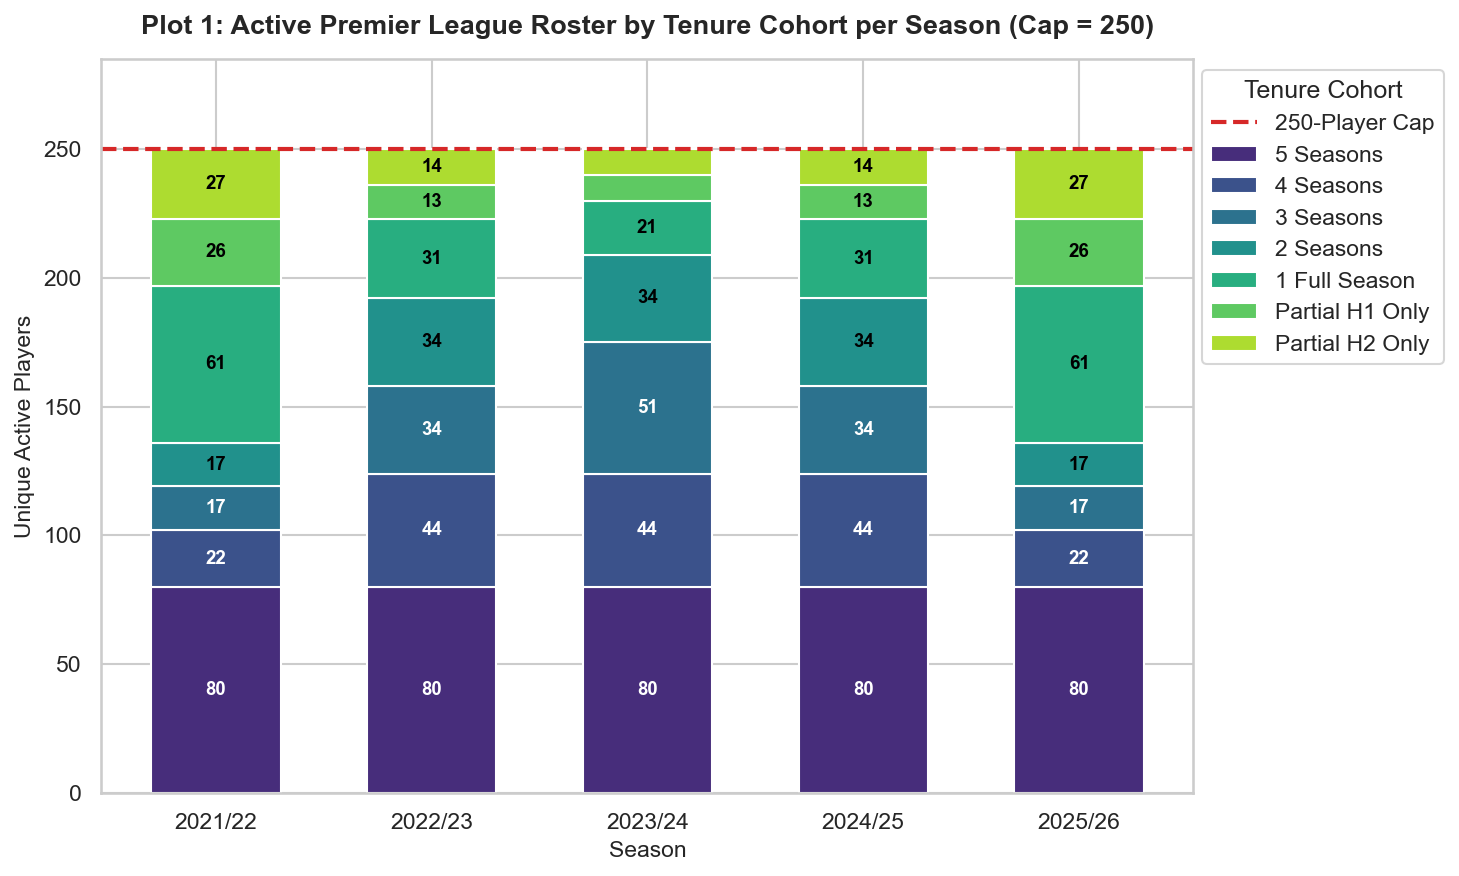

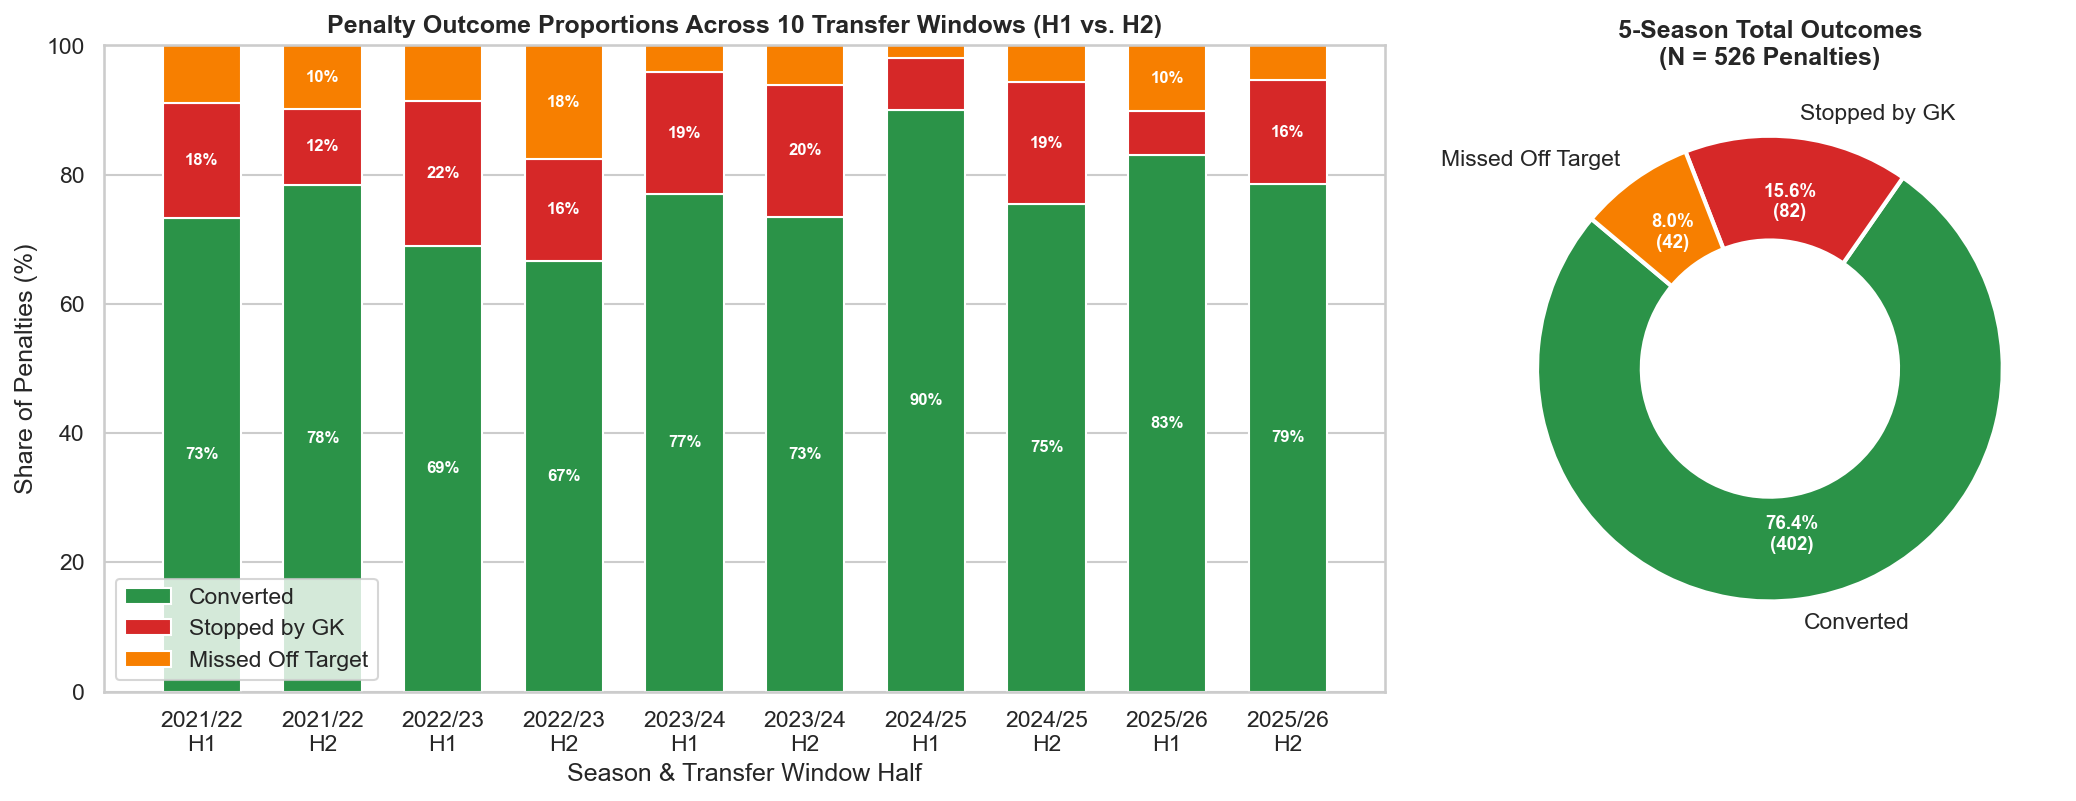

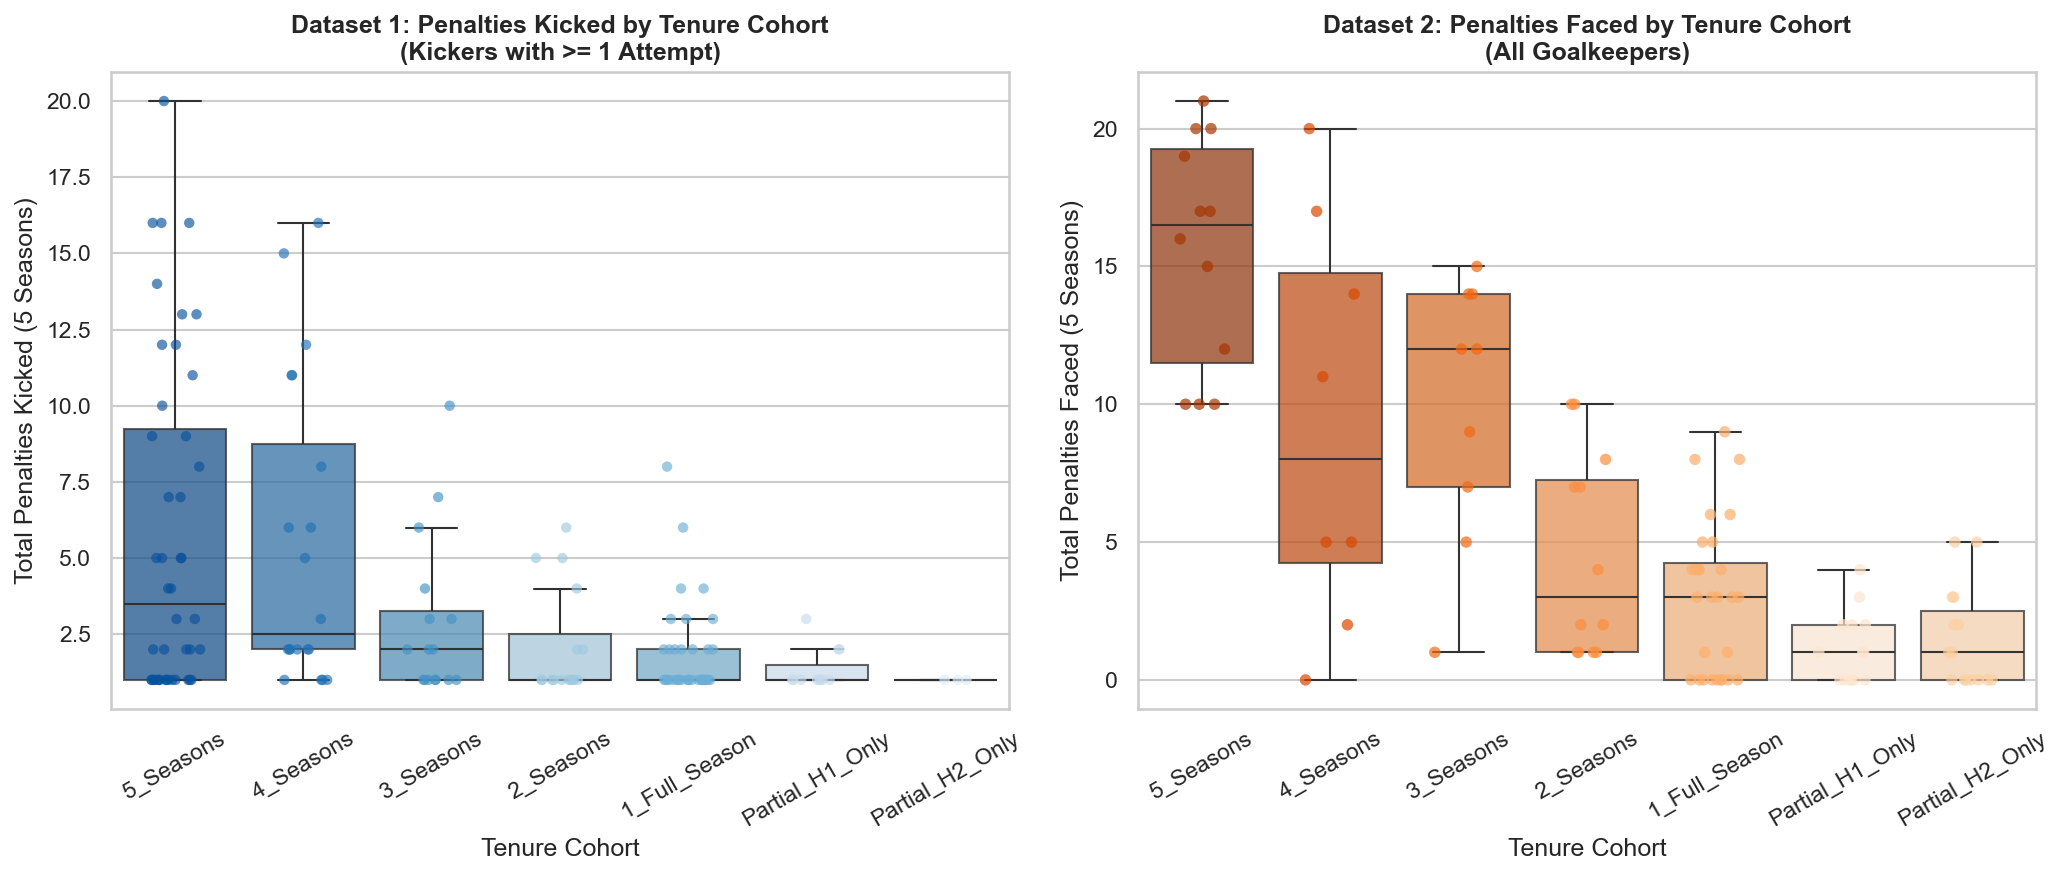

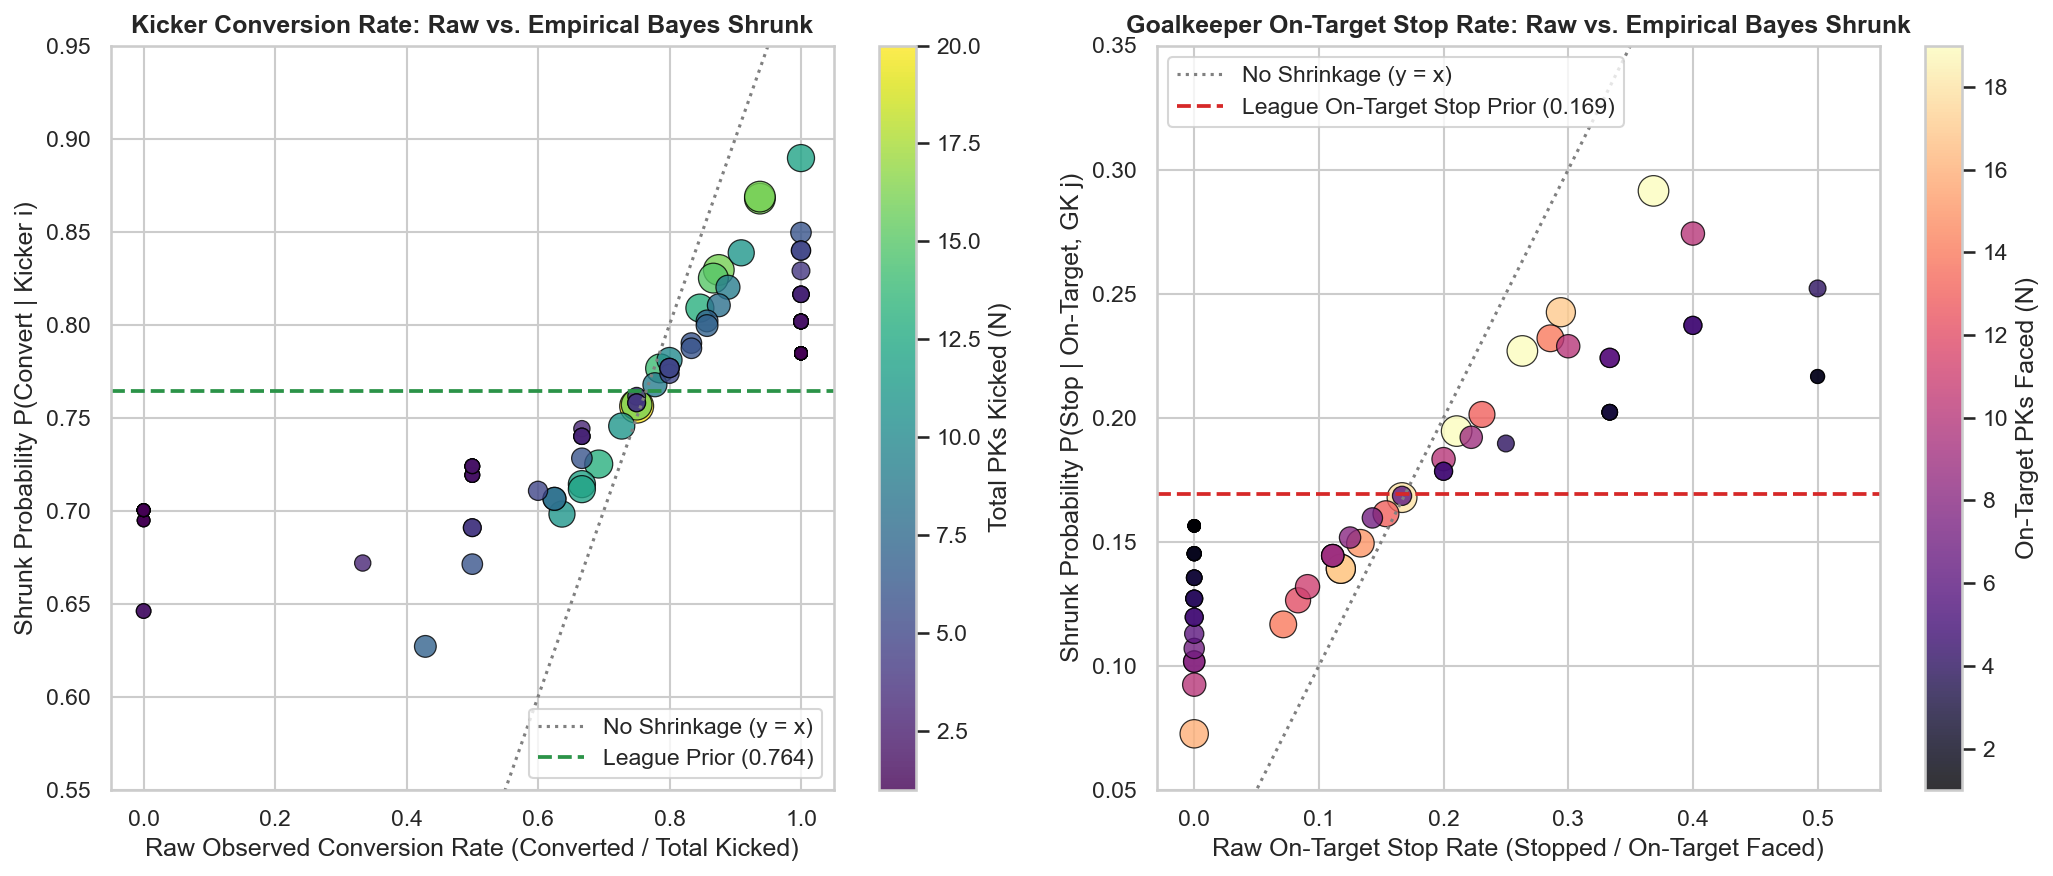

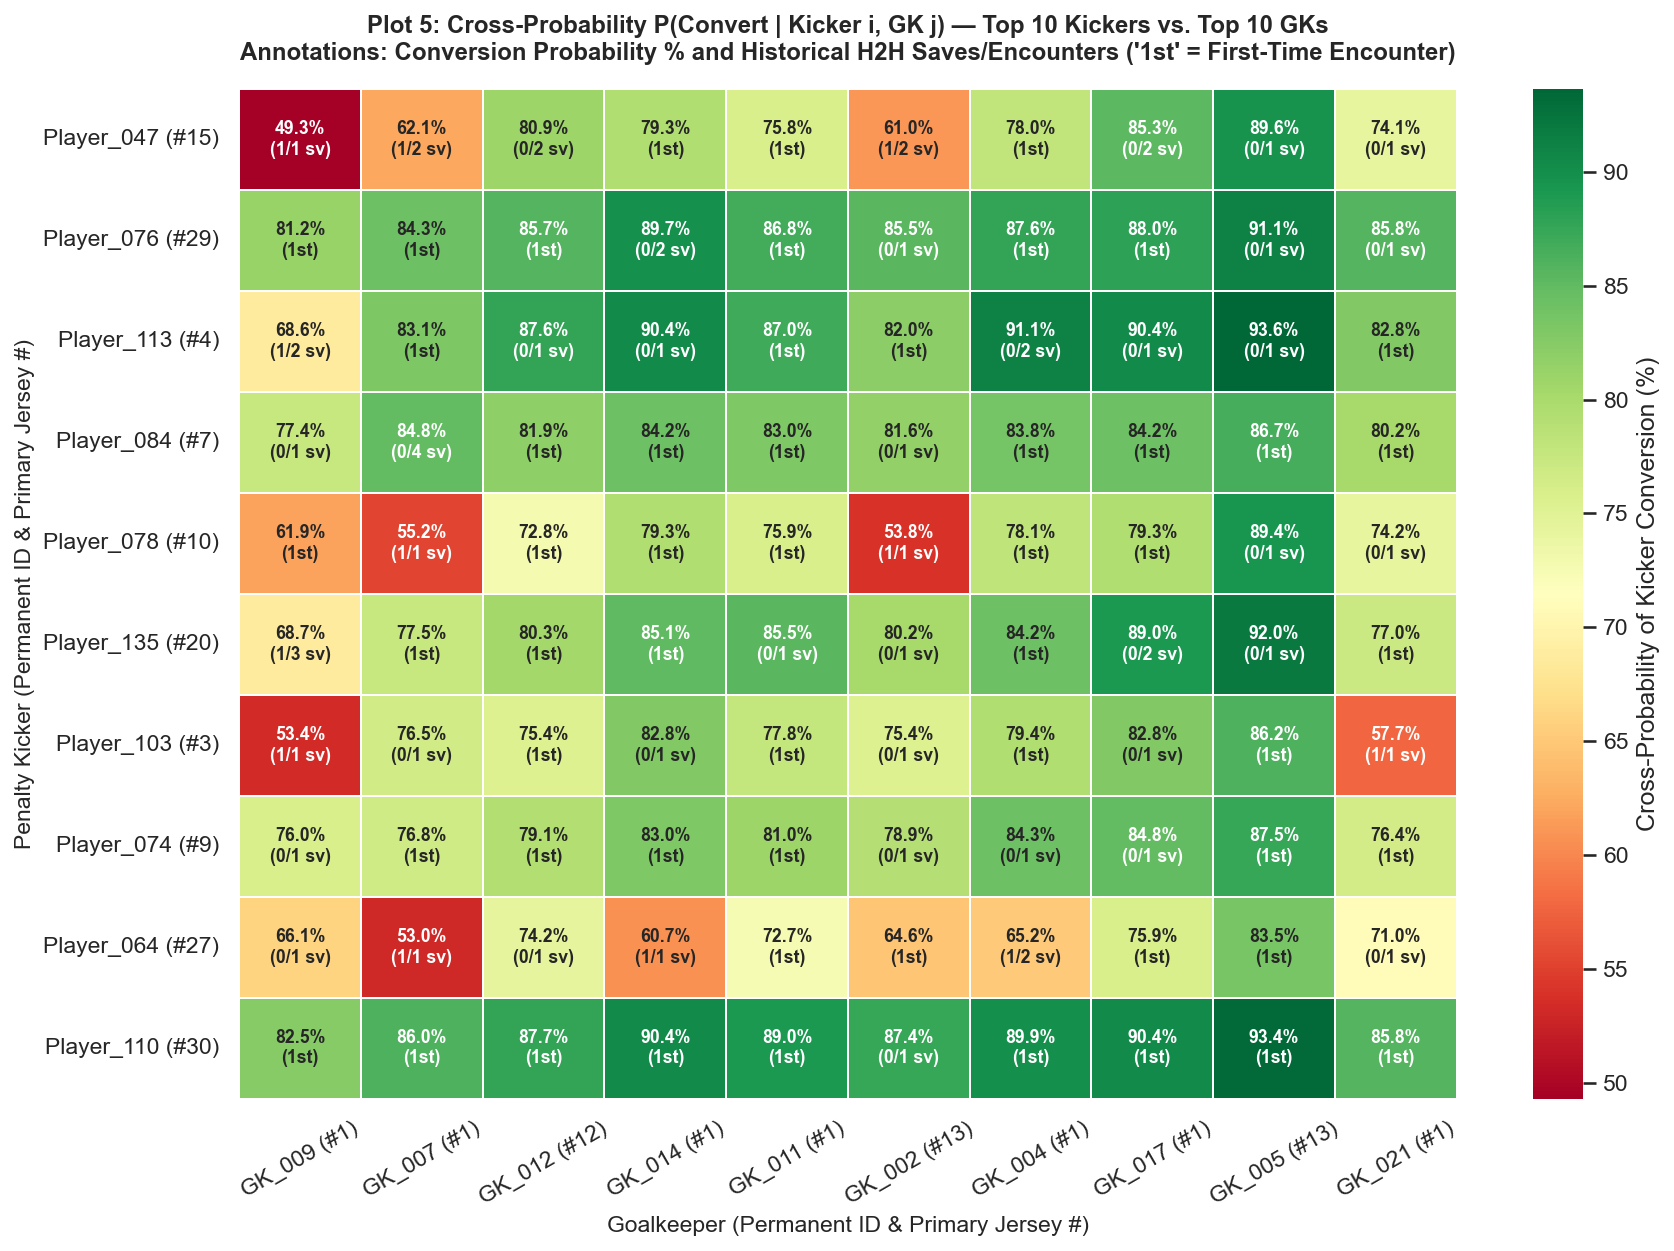

In [11]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# PILLAR 6: 5-CHART DIAGNOSTIC & ANALYTICAL PLOTS SUITE (INLINE DISPLAY)
# ==============================================================================

TENURE_ORDER = [
    "5_Seasons",
    "4_Seasons",
    "3_Seasons",
    "2_Seasons",
    "1_Full_Season",
    "Partial_H1_Only",
    "Partial_H2_Only",
]

OUTCOME_COLORS = {
    "Converted": "#2b9348",         # Rich green
    "Stopped_by_GK": "#d62828",     # Crimson red
    "Missed_Off_Target": "#f77f00", # Amber orange
}


class SyntheticDataPlotSuite:
    """
    Generates and displays the 5 diagnostic & analytical plots inline
    within a Jupyter/Colab Notebook.
    """
    def __init__(
        self,
        df_half_rosters: pd.DataFrame,
        dataset_1_enriched: pd.DataFrame,
        dataset_2_enriched: pd.DataFrame,
        dataset_3_events: pd.DataFrame,
        prob_engine,
    ):
        self.df_rosters = df_half_rosters
        self.d1 = dataset_1_enriched
        self.d2 = dataset_2_enriched
        self.d3 = dataset_3_events
        self.prob_engine = prob_engine

        # Apply clean visual theme
        sns.set_theme(style="whitegrid", context="notebook")

    def plot_1_active_roster_cohorts(self):
        """
        Plot 1: Stacked Bar Chart of Unique Active Players per Season by Tenure Cohort
        """
        season_cohort = (
            self.df_rosters.groupby(["season", "tenure_category"])["player_number"]
            .nunique()
            .unstack(fill_value=0)
        )
        cols = [c for c in TENURE_ORDER if c in season_cohort.columns]
        season_cohort = season_cohort[cols]

        fig, ax = plt.subplots(figsize=(10, 6), dpi=150)
        palette = sns.color_palette("viridis", len(cols))

        bottom = np.zeros(len(season_cohort))
        x_labels = season_cohort.index.tolist()

        for idx, col in enumerate(cols):
            values = season_cohort[col].to_numpy()
            ax.bar(
                x_labels,
                values,
                bottom=bottom,
                label=col.replace("_", " "),
                color=palette[idx],
                edgecolor="white",
                width=0.6,
            )
            for b_idx, val in enumerate(values):
                if val >= 12:
                    ax.text(
                        b_idx,
                        bottom[b_idx] + val / 2.0,
                        str(val),
                        ha="center",
                        va="center",
                        color="white" if idx < len(cols) // 2 else "black",
                        fontsize=9,
                        fontweight="bold",
                    )
            bottom += values

        ax.axhline(250, color="#d62828", linestyle="--", linewidth=2, label="250-Player Cap")
        ax.set_ylim(0, 285)
        ax.set_title(
            "Plot 1: Active Premier League Roster by Tenure Cohort per Season (Cap = 250)",
            fontsize=13,
            fontweight="bold",
            pad=12,
        )
        ax.set_xlabel("Season", fontsize=11)
        ax.set_ylabel("Unique Active Players", fontsize=11)
        ax.legend(loc="upper right", bbox_to_anchor=(1.24, 1.0), title="Tenure Cohort")
        plt.tight_layout()
        plt.show()

    def plot_2_penalty_outcomes_temporal(self):
        """
        Plot 2: Outcome breakdown across transfer windows + Global Donut Chart.
        """
        df_ev = self.d3.copy()
        df_ev["window_label"] = df_ev["season"] + "\n" + df_ev["half_season"]

        window_order = []
        for s in SEASONS:
            for h in ["H1", "H2"]:
                window_order.append(f"{s}\n{h}")

        win_counts = (
            df_ev.groupby(["window_label", "outcome"])
            .size()
            .unstack(fill_value=0)
            .reindex(window_order, fill_value=0)
        )
        win_pct = win_counts.div(win_counts.sum(axis=1), axis=0) * 100.0

        fig, (ax1, ax2) = plt.subplots(
            1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [2.2, 1]}, dpi=150
        )

        bottom = np.zeros(len(win_pct))
        for outcome in ["Converted", "Stopped_by_GK", "Missed_Off_Target"]:
            vals = win_pct[outcome].to_numpy()
            ax1.bar(
                win_pct.index,
                vals,
                bottom=bottom,
                color=OUTCOME_COLORS[outcome],
                edgecolor="white",
                width=0.65,
                label=outcome.replace("_", " "),
            )
            for i, v in enumerate(vals):
                if v >= 9.0:
                    ax1.text(
                        i,
                        bottom[i] + v / 2.0,
                        f"{v:.0f}%",
                        ha="center",
                        va="center",
                        color="white",
                        fontsize=8,
                        fontweight="bold",
                    )
            bottom += vals

        ax1.set_ylim(0, 100)
        ax1.set_title(
            "Penalty Outcome Proportions Across 10 Transfer Windows (H1 vs. H2)",
            fontsize=12,
            fontweight="bold",
        )
        ax1.set_ylabel("Share of Penalties (%)")
        ax1.set_xlabel("Season & Transfer Window Half")
        ax1.legend(loc="lower left", frameon=True)

        total_counts = df_ev["outcome"].value_counts().reindex(
            ["Converted", "Stopped_by_GK", "Missed_Off_Target"]
        )
        wedges, texts, autotexts = ax2.pie(
            total_counts.values,
            labels=[k.replace("_", " ") for k in total_counts.index],
            autopct=lambda pct: f"{pct:.1f}%\n({int(round(pct/100.* len(df_ev)))})",
            startangle=140,
            colors=[OUTCOME_COLORS[k] for k in total_counts.index],
            pctdistance=0.72,
            wedgeprops={"width": 0.45, "edgecolor": "white", "linewidth": 2},
        )
        for autotext in autotexts:
            autotext.set_color("white")
            autotext.set_fontsize(9)
            autotext.set_fontweight("bold")

        ax2.set_title(
            f"5-Season Total Outcomes\n(N = {len(df_ev)} Penalties)",
            fontsize=12,
            fontweight="bold",
        )
        plt.tight_layout()
        plt.show()

    def plot_3_exposure_by_tenure(self):
        """
        Plot 3: Box-and-Strip Plot of Penalties Kicked and Faced across Tenure Tiers.
        """
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=150)

        k_active = self.d1[self.d1["Total_PK_Kicked"] > 0].copy()
        sns.boxplot(
            data=k_active,
            x="tenure_category",
            y="Total_PK_Kicked",
            hue="tenure_category",
            order=TENURE_ORDER,
            ax=ax1,
            palette="Blues_r",
            fliersize=0,
            boxprops={"alpha": 0.75},
            legend=False,
        )
        sns.stripplot(
            data=k_active,
            x="tenure_category",
            y="Total_PK_Kicked",
            hue="tenure_category",
            order=TENURE_ORDER,
            ax=ax1,
            palette="Blues_r",
            alpha=0.65,
            jitter=0.2,
            size=5,
            legend=False,
        )
        ax1.set_title(
            "Dataset 1: Penalties Kicked by Tenure Cohort\n(Kickers with >= 1 Attempt)",
            fontsize=12,
            fontweight="bold",
        )
        ax1.set_xlabel("Tenure Cohort")
        ax1.set_ylabel("Total Penalties Kicked (5 Seasons)")
        ax1.tick_params(axis="x", rotation=30)

        sns.boxplot(
            data=self.d2,
            x="tenure_category",
            y="Total_PK_Faced",
            hue="tenure_category",
            order=TENURE_ORDER,
            ax=ax2,
            palette="Oranges_r",
            fliersize=0,
            boxprops={"alpha": 0.75},
            legend=False,
        )
        sns.stripplot(
            data=self.d2,
            x="tenure_category",
            y="Total_PK_Faced",
            hue="tenure_category",
            order=TENURE_ORDER,
            ax=ax2,
            palette="Oranges_r",
            alpha=0.7,
            jitter=0.2,
            size=5.5,
            legend=False,
        )
        ax2.set_title(
            "Dataset 2: Penalties Faced by Tenure Cohort\n(All Goalkeepers)",
            fontsize=12,
            fontweight="bold",
        )
        ax2.set_xlabel("Tenure Cohort")
        ax2.set_ylabel("Total Penalties Faced (5 Seasons)")
        ax2.tick_params(axis="x", rotation=30)

        plt.tight_layout()
        plt.show()

    def plot_4_empirical_bayes_shrinkage(self):
        """
        Plot 4: Empirical Bayes Shrinkage Diagnostic.
        """
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=150)

        k_sub = self.d1[self.d1["Total_PK_Kicked"] > 0].copy()
        sc1 = ax1.scatter(
            k_sub["raw_conv_prob"],
            k_sub["eb_prob_convert"],
            s=k_sub["Total_PK_Kicked"] * 12 + 25,
            c=k_sub["Total_PK_Kicked"],
            cmap="viridis",
            alpha=0.8,
            edgecolors="black",
            linewidth=0.6,
        )
        ax1.plot([0, 1], [0, 1], color="gray", linestyle=":", label="No Shrinkage (y = x)")
        ax1.axhline(
            self.prob_engine.league_p_conv_overall,
            color="#2b9348",
            linestyle="--",
            linewidth=1.8,
            label=f"League Prior ({self.prob_engine.league_p_conv_overall:.3f})",
        )
        ax1.set_xlim(-0.05, 1.05)
        ax1.set_ylim(0.55, 0.95)
        ax1.set_title(
            "Kicker Conversion Rate: Raw vs. Empirical Bayes Shrunk",
            fontsize=12,
            fontweight="bold",
        )
        ax1.set_xlabel("Raw Observed Conversion Rate (Converted / Total Kicked)")
        ax1.set_ylabel("Shrunk Probability P(Convert | Kicker i)")
        ax1.legend(loc="lower right")
        cbar1 = plt.colorbar(sc1, ax=ax1)
        cbar1.set_label("Total PKs Kicked (N)")

        g_sub = self.d2[
            (self.d2["Stopped_by_GK"] + self.d2["Converted_by_Kicker"]) > 0
        ].copy()
        g_sub["on_target_faced"] = (
            g_sub["Stopped_by_GK"] + g_sub["Converted_by_Kicker"]
        )
        sc2 = ax2.scatter(
            g_sub["raw_stop_prob_on_target"],
            g_sub["eb_prob_stop_given_target"],
            s=g_sub["on_target_faced"] * 10 + 25,
            c=g_sub["on_target_faced"],
            cmap="magma",
            alpha=0.8,
            edgecolors="black",
            linewidth=0.6,
        )
        ax2.plot([0, 0.6], [0, 0.6], color="gray", linestyle=":", label="No Shrinkage (y = x)")
        ax2.axhline(
            self.prob_engine.league_p_stop_given_target,
            color="#d62828",
            linestyle="--",
            linewidth=1.8,
            label=f"League On-Target Stop Prior ({self.prob_engine.league_p_stop_given_target:.3f})",
        )
        ax2.set_xlim(-0.03, 0.55)
        ax2.set_ylim(0.05, 0.35)
        ax2.set_title(
            "Goalkeeper On-Target Stop Rate: Raw vs. Empirical Bayes Shrunk",
            fontsize=12,
            fontweight="bold",
        )
        ax2.set_xlabel("Raw On-Target Stop Rate (Stopped / On-Target Faced)")
        ax2.set_ylabel("Shrunk Probability P(Stop | On-Target, GK j)")
        ax2.legend(loc="upper left")
        cbar2 = plt.colorbar(sc2, ax=ax2)
        cbar2.set_label("On-Target PKs Faced (N)")

        plt.tight_layout()
        plt.show()

    def plot_5_cross_probability_heatmap(self):
        """
        Plot 5: 10x10 Cross-Probability Heatmap for Top 10 Kickers vs. Top 10 Goalkeepers.
        """
        top_kickers = self.d1.head(10)[["player_number", "player_name", "primary_squad_number"]]
        top_gks = self.d2.head(10)[["player_number", "player_name", "primary_squad_number"]]

        prob_matrix = np.zeros((len(top_kickers), len(top_gks)))
        annot_matrix = np.empty((len(top_kickers), len(top_gks)), dtype=object)

        k_labels = [
            f"{r['player_name']} (#{r['primary_squad_number']})"
            for _, r in top_kickers.iterrows()
        ]
        g_labels = [
            f"{r['player_name']} (#{r['primary_squad_number']})"
            for _, r in top_gks.iterrows()
        ]

        for i_idx, (_, k_row) in enumerate(top_kickers.iterrows()):
            for j_idx, (_, g_row) in enumerate(top_gks.iterrows()):
                res = self.prob_engine.predict_matchup(
                    int(k_row["player_number"]), int(g_row["player_number"])
                )
                p_conv = res["cross_prob_convert"]
                n_tot = res["prior_h2h_total"]
                n_stop = res["prior_h2h_stopped_by_gk"]

                prob_matrix[i_idx, j_idx] = p_conv
                if n_tot == 0:
                    annot_matrix[i_idx, j_idx] = f"{p_conv*100:.1f}%\n(1st)"
                else:
                    annot_matrix[i_idx, j_idx] = f"{p_conv*100:.1f}%\n({n_stop}/{n_tot} sv)"

        fig, ax = plt.subplots(figsize=(12, 8.5), dpi=150)
        sns.heatmap(
            prob_matrix * 100.0,
            annot=annot_matrix,
            fmt="",
            cmap="RdYlGn",
            xticklabels=g_labels,
            yticklabels=k_labels,
            cbar_kws={"label": "Cross-Probability of Kicker Conversion (%)"},
            linewidths=0.8,
            linecolor="white",
            annot_kws={"size": 8.5, "weight": "bold"},
            ax=ax,
        )
        ax.set_title(
            "Plot 5: Cross-Probability P(Convert | Kicker i, GK j) — Top 10 Kickers vs. Top 10 GKs\n"
            "Annotations: Conversion Probability % and Historical H2H Saves/Encounters ('1st' = First-Time Encounter)",
            fontsize=11.5,
            fontweight="bold",
            pad=14,
        )
        ax.set_xlabel("Goalkeeper (Permanent ID & Primary Jersey #)", fontsize=11)
        ax.set_ylabel("Penalty Kicker (Permanent ID & Primary Jersey #)", fontsize=11)
        ax.tick_params(axis="x", rotation=30)
        ax.tick_params(axis="y", rotation=0)

        plt.tight_layout()
        plt.show()

    def generate_all_plots(self):
        """
        Renders all 5 plots inline sequentially inside the notebook cell.
        """
        self.plot_1_active_roster_cohorts()
        self.plot_2_penalty_outcomes_temporal()
        self.plot_3_exposure_by_tenure()
        self.plot_4_empirical_bayes_shrinkage()
        self.plot_5_cross_probability_heatmap()


# ==============================================================================
# CALLING THE GENERATION METHOD IN YOUR NOTEBOOK CELL
# ==============================================================================
if __name__ == "__main__":
    # Ensure all previous pillars (1-4) have been executed first to define:
    # df_half_rosters, prob_engine.dataset_1_enriched, prob_engine.dataset_2_enriched, dataset_3_events, prob_engine
    
    plot_suite = SyntheticDataPlotSuite(
        df_half_rosters=df_half_rosters,
        dataset_1_enriched=prob_engine.dataset_1_enriched,
        dataset_2_enriched=prob_engine.dataset_2_enriched,
        dataset_3_events=dataset_3_events,
        prob_engine=prob_engine,
    )

    # Calling the generation method will display all 5 charts inline
    plot_suite.generate_all_plots()

### Pillar 7: 

It implements the SyntheticDataExporter, which takes all your generated datasets and exports them into three optimized formats:

1. Indexed SQLite Database (output_data/epl_synthetic_penalties.db): Pre-built with indexes on player_number, (kicker_number, gk_number), and date for fast historical querying.

2. Apache Parquet Files (output_data/parquet/*.parquet): Columnar and compressed files preserving strict data types.

3. CSV Files (output_data/csv/*.csv): Human-readable flat file backups.

In [17]:
import os
import sqlite3
import pandas as pd

class SyntheticDataExporter:
    """
    Exports all simulation tables (Master Players, Half-Season Rosters,
    Dataset 1 Kickers, Dataset 2 Goalkeepers, and Dataset 3 Matchup Events)
    to SQLite, Parquet, and CSV formats, safely converting list-type columns to strings.
    """
    def __init__(
        self,
        df_master_players: pd.DataFrame,
        df_half_rosters: pd.DataFrame,
        dataset_1_enriched: pd.DataFrame,
        dataset_2_enriched: pd.DataFrame,
        dataset_3_events: pd.DataFrame,
        base_dir: str = "output_data",
    ):
        self.df_master = df_master_players.copy()
        self.df_rosters = df_half_rosters.copy()
        self.d1 = dataset_1_enriched.copy()
        self.d2 = dataset_2_enriched.copy()
        self.d3 = dataset_3_events.copy()

        self.base_dir = base_dir
        #self.parquet_dir = os.path.join(self.base_dir, "parquet")
        #self.csv_dir = os.path.join(self.base_dir, "csv")
        self.sqlite_path = os.path.join(self.base_dir, "epl_synthetic_penalties.db")

    def _sanitize_lists(self, df: pd.DataFrame) -> pd.DataFrame:
        """
        Converts any columns containing lists into string representations 
        so SQLite and Parquet can handle them without throwing errors.
        """
        df_clean = df.copy()
        for col in df_clean.columns:
            # Check if any element in the column is a list
            if df_clean[col].apply(lambda x: isinstance(x, list)).any():
                df_clean[col] = df_clean[col].apply(
                    lambda x: ",".join(map(str, x)) if isinstance(x, list) else x
                )
        return df_clean

    def export_all(self):
        """
        Executes exports across SQLite, Parquet, and CSV, and creates performance indexes.
        """
        os.makedirs(self.base_dir, exist_ok=True)
        #os.makedirs(self.parquet_dir, exist_ok=True)
        #os.makedirs(self.csv_dir, exist_ok=True)

        # Sanitize all dataframes to convert list columns to strings
        master_clean = self._sanitize_lists(self.df_master)
        rosters_clean = self._sanitize_lists(self.df_rosters)
        d1_clean = self._sanitize_lists(self.d1)
        d2_clean = self._sanitize_lists(self.d2)
        d3_clean = self._sanitize_lists(self.d3)

        # ----------------------------------------------------------------------
        # 1. EXPORT TO CSV FILES
        # ----------------------------------------------------------------------
        #master_clean.to_csv(os.path.join(self.base_dir, "master_players.csv"), index=False)
        #rosters_clean.to_csv(os.path.join(self.base_dir, "half_season_rosters.csv"), index=False)
        #d1_clean.to_csv(os.path.join(self.base_dir, "dataset_1_kickers.csv"), index=False)
        #d2_clean.to_csv(os.path.join(self.base_dir, "dataset_2_goalkeepers.csv"), index=False)
        #d3_clean.to_csv(os.path.join(self.base_dir, "dataset_3_matchup_events.csv"), index=False)

        # ----------------------------------------------------------------------
        # 2. EXPORT TO APACHE PARQUET FILES
        # ----------------------------------------------------------------------
        #master_clean.to_parquet(os.path.join(self.parquet_dir, "master_players.parquet"), index=False)
        #rosters_clean.to_parquet(os.path.join(self.parquet_dir, "half_season_rosters.parquet"), index=False)
        #d1_clean.to_parquet(os.path.join(self.parquet_dir, "dataset_1_kickers.parquet"), index=False)
        #d2_clean.to_parquet(os.path.join(self.parquet_dir, "dataset_2_goalkeepers.parquet"), index=False)
        #d3_clean.to_parquet(os.path.join(self.parquet_dir, "dataset_3_matchup_events.parquet"), index=False)

        # ----------------------------------------------------------------------
        # 3. EXPORT TO INDEXED SQLITE DATABASE
        # ----------------------------------------------------------------------
        with sqlite3.connect(self.sqlite_path) as conn:
            master_clean.to_sql("players_master", conn, if_exists="replace", index=False)
            rosters_clean.to_sql("season_half_rosters", conn, if_exists="replace", index=False)
            d1_clean.to_sql("dataset_1_kickers", conn, if_exists="replace", index=False)
            d2_clean.to_sql("dataset_2_goalkeepers", conn, if_exists="replace", index=False)
            d3_clean.to_sql("dataset_3_matchup_events", conn, if_exists="replace", index=False)

            # Create performance indexes for rapid probability retrieval & backtesting
            cursor = conn.cursor()
            cursor.execute("CREATE INDEX IF NOT EXISTS idx_d3_kicker ON dataset_3_matchup_events(kicker_number);")
            cursor.execute("CREATE INDEX IF NOT EXISTS idx_d3_gk ON dataset_3_matchup_events(gk_number);")
            cursor.execute("CREATE INDEX IF NOT EXISTS idx_d3_pair ON dataset_3_matchup_events(kicker_number, gk_number);")
            cursor.execute("CREATE INDEX IF NOT EXISTS idx_d3_date ON dataset_3_matchup_events(date);")
            cursor.execute("CREATE INDEX IF NOT EXISTS idx_rosters_player ON season_half_rosters(player_number, season_idx, half_season);")
            conn.commit()

        print(f"Successfully exported all simulation tables to:\n"
              f" - SQLite DB: {self.sqlite_path}\n"
        )
              #f" - Parquet Folder: {self.parquet_dir}/\n"
              #f" - CSV Folder: {self.csv_dir}/")

# ==============================================================================
# EXECUTION IN YOUR NOTEBOOK CELL
# ==============================================================================
if __name__ == "__main__":
    # Ensure all previous pillars have been executed successfully
    exporter = SyntheticDataExporter(
        df_master_players=df_master_players,
        df_half_rosters=df_half_rosters,
        dataset_1_enriched=prob_engine.dataset_1_enriched,
        dataset_2_enriched=prob_engine.dataset_2_enriched,
        dataset_3_events=dataset_3_events,
        base_dir="output_data",
    )
    exporter.export_all()

Successfully exported all simulation tables to:
 - SQLite DB: output_data\epl_synthetic_penalties.db

